# Data Understanding - Manu

**Equipo PINU · Fase 2 de CRISP-DM**

**Objetivo de negocio:** identificar problemas de cola mediante la detección de anomalías en el ordeñamiento.
**Objetivo de minería de datos:** clasificar los posibles tipos de evento que se presentan en el ordeño.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

# Colores fijos para todas las graficas
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"

sns.set_theme(style="whitegrid", rc={
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": "#e6e5e1",
    "axes.edgecolor": "#c3c2b7",
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "figure.dpi": 110,
})

In [2]:
# Busca la raiz del repo (la carpeta que contiene Data) sin importar desde donde se ejecute
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Data").exists())

# id_vaca y misc_eo_po son identificadores (hash), no cantidades: se leen como texto
df = pd.read_csv(raiz / "Data" / "dataset_vacas_anonimo.csv", dtype={"id_vaca": str, "misc_eo_po": str})
print(f"Registros: {df.shape[0]:,} | Columnas: {df.shape[1]}")

Registros: 7,249 | Columnas: 36


## 1. Visualizar y consultar los datos

Cada instancia es una visita de una vaca. Las columnas vienen en grupos: `main_*` (resumen de la sesión), `estado_*` (eventos ocurridos), mediciones por cuarto de la ubre y `misc_*`.

In [3]:
df.head()

,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg,estado_numero_de_ordeno,estado_rcs_1000_celulas_ml,estado_patada,estado_incompleto,estado_pezones_no_encontrados,estado_amd_ubre,estado_amd_pezon,media_de_los_flujos_kg_min_di,media_de_los_flujos_kg_min_dd,media_de_los_flujos_kg_min_ti,media_de_los_flujos_kg_min_td,sangre_ppm_di,sangre_ppm_dd,sangre_ppm_ti,sangre_ppm_td,conductividad_ms_cm_di,conductividad_ms_cm_dd,conductividad_ms_cm_ti,conductividad_ms_cm_td,misc_eo_po,misc_usuario,misc_destino_leche,misc_razon_de_la_desviacion,flujos_maximos_kg_min_di,flujos_maximos_kg_min_dd,flujos_maximos_kg_min_ti,flujos_maximos_kg_min_td,producciones_kg_di,producciones_kg_dd,producciones_kg_ti,producciones_kg_td
0,3d995085,01/03/2025 05:37 a. m.,Ordeño,09:58,23.96,1.0,NaN,NaN,NaN,NaN,1.0,NaN,1.26,1.74,1.86,1.62,0.0,0.0,0.0,0.0,4.92,5.16,5.48,5.21,7063e4b1,NaN,Tanque,NaN,1.74,2.16,2.40,2.10,6.11,5.56,3.33,8.96
1,3d995085,01/03/2025 07:15 p. m.,Ordeño,06:51,17.20,2.0,NaN,DI,NaN,NaN,1.0,NaN,1.14,1.80,2.04,1.74,0.0,0.0,0.0,0.0,4.58,4.84,5.26,4.88,7063e4b1,NaN,Tanque,NaN,2.10,2.34,2.52,2.28,3.23,4.86,2.69,6.42
2,3d995085,02/03/2025 02:24 a. m.,Ordeño,07:23,11.13,1.0,NaN,NaN,NaN,NaN,1.0,TI,1.20,1.44,1.74,1.44,0.0,0.0,0.0,0.0,4.26,4.38,5.00,4.52,7063e4b1,NaN,Tanque,NaN,1.68,1.98,2.34,1.92,4.40,2.43,1.15,3.15
3,3d995085,02/03/2025 07:51 p. m.,Ordeño,08:29,20.64,2.0,NaN,NaN,NaN,NaN,1.0,NaN,1.20,1.68,1.92,1.68,0.0,0.0,0.0,0.0,4.36,4.77,5.01,4.82,7063e4b1,NaN,Tanque,NaN,2.10,2.22,2.52,2.40,5.72,4.88,3.10,6.94
4,3d995085,03/03/2025 06:00 a. m.,Ordeño,05:05,9.59,1.0,NaN,NaN,NaN,NaN,1.0,NaN,1.14,1.62,1.80,1.50,0.0,0.0,0.0,0.0,4.13,4.42,4.36,4.44,7063e4b1,NaN,Tanque,NaN,1.80,2.10,2.28,1.98,2.69,2.41,1.44,3.05


In [4]:
# Consulta: que tipo de visitas hay y en que robot ocurren
pd.crosstab(df["main_accion"], df["misc_eo_po"], margins=True, margins_name="Total")

misc_eo_po,7063e4b1,86696b37,b96e85be,Total
main_accion,,,,
Echada sin ordeñar,42,11,8,61
Ordeño,4134,1615,1267,7016
Rechazada,100,48,24,172
Total,4276,1674,1299,7249


In [5]:
# Consulta: cuantos registros tiene cada vaca
registros_vaca = df.groupby("id_vaca").size().sort_values()
print(f"Vacas: {registros_vaca.size} | min: {registros_vaca.min()} | mediana: {registros_vaca.median():.0f} | max: {registros_vaca.max()}")
print("\nVacas con menos de 30 registros:")
print(registros_vaca[registros_vaca < 30].to_string())

Vacas: 34 | min: 2 | mediana: 248 | max: 421

Vacas con menos de 30 registros:
id_vaca
ed537d8a     2
8c740a5e     8
48978300    10


In [6]:
# Consulta: ejemplo de sesiones con ordeño incompleto
columnas_consulta = ["id_vaca", "main_hora_de_inicio", "main_duracion_mm_ss", "main_produccion_kg",
                     "estado_patada", "estado_incompleto", "estado_pezones_no_encontrados", "misc_eo_po"]
df[df["estado_incompleto"].notna()][columnas_consulta].head(8)

,id_vaca,main_hora_de_inicio,main_duracion_mm_ss,main_produccion_kg,estado_patada,estado_incompleto,estado_pezones_no_encontrados,misc_eo_po
40,3d995085,25/03/2025 12:35 p. m.,04:23,3.40,NaN,Todos,NaN,7063e4b1
49,3d995085,30/03/2025 02:36 p. m.,04:44,5.74,NaN,Todos,NaN,7063e4b1
76,3d995085,16/04/2025 08:21 p. m.,03:27,1.05,NaN,Todos,"DI,DD,TI",7063e4b1
86,3d995085,23/04/2025 10:25 p. m.,10:50,21.58,NaN,TI,TI,7063e4b1
88,3d995085,25/04/2025 12:24 p. m.,07:49,12.94,NaN,TI,NaN,7063e4b1
98,3d995085,30/04/2025 11:32 p. m.,11:08,18.78,NaN,TI,TI,7063e4b1
100,3d995085,02/05/2025 03:43 a. m.,07:21,13.61,NaN,TI,NaN,7063e4b1
101,3d995085,02/05/2025 09:54 p. m.,09:18,19.38,NaN,TI,TI,7063e4b1


In [7]:
# Estadisticos descriptivos de las variables numericas
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
main_produccion_kg,7016.0,13.72,5.33,0.0,9.86,13.26,17.06,39.47
estado_numero_de_ordeno,7016.0,1.77,0.81,1.0,1.00,2.00,2.00,5.00
estado_rcs_1000_celulas_ml,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_amd_ubre,7016.0,0.15,0.36,0.0,0.00,0.00,0.00,1.00
media_de_los_flujos_kg_min_di,7016.0,1.03,0.43,0.0,0.78,1.02,1.32,4.98
media_de_los_flujos_kg_min_dd,7013.0,1.11,0.40,0.0,0.84,1.08,1.38,2.64
media_de_los_flujos_kg_min_ti,6717.0,1.05,0.49,0.0,0.78,1.08,1.32,4.08
media_de_los_flujos_kg_min_td,6952.0,1.07,0.45,0.0,0.84,1.08,1.32,2.82
sangre_ppm_di,7016.0,23.16,287.06,0.0,0.00,0.00,0.00,7997.00
sangre_ppm_dd,7013.0,8.60,89.22,0.0,0.00,0.00,0.00,2786.00


**Observaciones**

- Hay tres tipos de visita: `Ordeño`, `Rechazada` (la vaca entra pero el robot no la ordeña) y `Echada sin ordeñar`. Solo las de `Ordeño` tienen mediciones.
- El historial por vaca es muy desigual: 3 vacas (`ed537d8a`, `8c740a5e`, `48978300`) tienen 10 registros o menos, porque aparecen hasta la última semana del periodo.
- `sangre_ppm_*` es casi siempre 0 con máximos cercanos a 8,000: distribución muy sesgada.
- `conductividad_ms_cm_*` tiene mínimo 0, valor físicamente imposible para leche; se revisa en la sección de nulos.
- Se tiene medida la hora de inicio y la duración del ordeño, más no se tiene datos sobre la hora de salida.

### Descripción de cada columna:

Cada fila es una visita de una vaca a una máquina de ordeño. Los sufijos `_di`, `_dd`, `_ti` y `_td` indican el cuarto de la ubre: delantero izquierdo, delantero derecho, trasero izquierdo y trasero derecho.

**Identificación y resumen de la sesión**

| Columna | Descripción | Tipo |
| :-- | :-- | :-- |
| `id_vaca` | Identificador de la vaca, anonimizado con un hash. | Identificador |
| `main_hora_de_inicio` | Fecha y hora en que inició la visita (`dd/mm/aaaa hh:mm a. m./p. m.`), con precisión de minutos. | Fecha y hora (texto) |
| `main_accion` | Resultado de la visita: `Ordeño`, `Rechazada` (la vaca entró pero no fue ordeñada) o `Echada sin ordeñar`. | Categórica |
| `main_duracion_mm_ss` | Duración de la visita en minutos y segundos. | Duración (texto) |
| `main_produccion_kg` | Leche total obtenida en el ordeño, en kg. Es la suma de los cuatro cuartos. | Numérica continua |

**Estado y eventos del ordeño**

| Columna | Descripción | Tipo |
| :-- | :-- | :-- |
| `estado_numero_de_ordeno` | Número consecutivo del ordeño de la vaca en el día (1 a 5). | Numérica discreta |
| `estado_rcs_1000_celulas_ml` | Recuento de células somáticas, en miles de células por ml. Indicador de salud de la ubre. **Vacía en todos los registros.** | Numérica (sin datos) |
| `estado_patada` | Cuartos en los que la vaca pateó la pezonera. Vacío = no hubo patada. | Evento por cuarto |
| `estado_incompleto` | Cuartos cuyo ordeño no se completó. Vacío = ordeño completo. | Evento por cuarto |
| `estado_pezones_no_encontrados` | Cuartos en los que la máquina no logró localizar el pezón. Vacío = se encontraron todos. | Evento por cuarto |
| `estado_amd_ubre` | Alerta AMD a nivel de ubre (0 = sin alerta, 1 = con alerta). *Significado de AMD por confirmar.* | Binaria |
| `estado_amd_pezon` | Cuartos con alerta AMD. Vacío = sin alerta. *Significado de AMD por confirmar.* | Evento por cuarto |

En las columnas de evento por cuarto el valor es la lista de cuartos afectados (`TI`, `DI,TD`) o `Todos`.

**Mediciones por cuarto** (cuatro columnas cada una: `_di`, `_dd`, `_ti`, `_td`)

| Columnas | Descripción | Tipo |
| :-- | :-- | :-- |
| `media_de_los_flujos_kg_min_*` | Flujo promedio de leche del cuarto durante el ordeño, en kg/min. | Numérica continua |
| `flujos_maximos_kg_min_*` | Flujo máximo de leche alcanzado en el cuarto, en kg/min. | Numérica continua |
| `producciones_kg_*` | Leche obtenida del cuarto, en kg. | Numérica continua |
| `sangre_ppm_*` | Sangre detectada en la leche del cuarto, en partes por millón. Normalmente es 0. | Numérica continua |
| `conductividad_ms_cm_*` | Conductividad eléctrica de la leche del cuarto, en mS/cm. Valores altos se asocian con mastitis. Un 0 se interpreta como lectura faltante. | Numérica continua |

**Otros**

| Columna | Descripción | Tipo |
| :-- | :-- | :-- |
| `misc_eo_po` | Máquina de ordeño en la que ocurrió la visita, anonimizada con un hash (3 máquinas). | Categórica |
| `misc_usuario` | Usuario que intervino en la sesión. **Vacía en todos los registros.** | Sin datos |
| `misc_destino_leche` | A dónde se envió la leche: `Tanque`, `Drenaje` (se desecha) o `Divert 3` (se desvía a una línea aparte). | Categórica |
| `misc_razon_de_la_desviacion` | Motivo por el que la leche no fue al tanque. Solo tiene un valor en todo el dataset. | Categórica (casi sin datos) |

## 2. Tipos de datos

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7249 entries, 0 to 7248
Data columns (total 36 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_vaca                        7249 non-null   str    
 1   main_hora_de_inicio            7249 non-null   str    
 2   main_accion                    7249 non-null   str    
 3   main_duracion_mm_ss            7249 non-null   str    
 4   main_produccion_kg             7016 non-null   float64
 5   estado_numero_de_ordeno        7016 non-null   float64
 6   estado_rcs_1000_celulas_ml     0 non-null      float64
 7   estado_patada                  1299 non-null   str    
 8   estado_incompleto              1014 non-null   str    
 9   estado_pezones_no_encontrados  1239 non-null   str    
 10  estado_amd_ubre                7016 non-null   float64
 11  estado_amd_pezon               802 non-null    str    
 12  media_de_los_flujos_kg_min_di  7016 non-null   float64
 13 

**Observaciones**

- El tipo que asigna pandas no coincide con el tipo real en varias columnas: la fecha, la hora de inicio y la duración están como texto, y `estado_numero_de_ordeno` / `estado_amd_ubre` aparecen como `float` solo porque tienen nulos.
- Las cuatro columnas de evento (`patada`, `incompleto`, `pezones_no_encontrados`, `amd_pezon`) no guardan sí/no, sino **la lista de cuartos afectados** (`TI`, `DI,TD`, `Todos`). Hay que convertirlas en variables utilizables.
- 21 columnas son mediciones continuas: la producción total más 5 magnitudes × 4 cuartos.

## 3. Nulos: cantidad y porcentaje

In [9]:
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2),
}).sort_values("porcentaje", ascending=False)

print(f"Celdas nulas: {df.isna().sum().sum():,} de {df.size:,} ({df.isna().sum().sum() / df.size:.1%})")
nulos

Celdas nulas: 53,810 de 260,964 (20.6%)


,nulos,porcentaje
estado_rcs_1000_celulas_ml,7249,100.00
misc_usuario,7249,100.00
misc_razon_de_la_desviacion,7248,99.99
estado_amd_pezon,6447,88.94
estado_incompleto,6235,86.01
estado_pezones_no_encontrados,6010,82.91
estado_patada,5950,82.08
sangre_ppm_ti,532,7.34
producciones_kg_ti,532,7.34
flujos_maximos_kg_min_ti,532,7.34


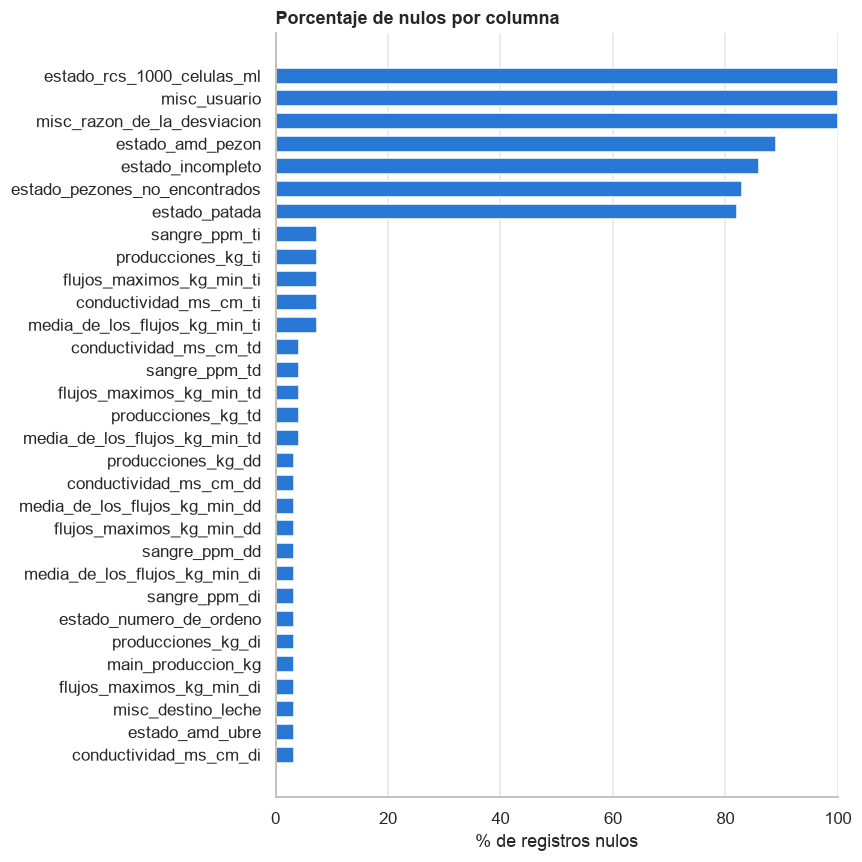

In [10]:
fig, ax = plt.subplots(figsize=(8, 8))
orden = nulos[nulos["nulos"] > 0].sort_values("porcentaje")
ax.barh(orden.index, orden["porcentaje"], color=AZUL, height=0.7)
ax.set_title("Porcentaje de nulos por columna")
ax.set_xlabel("% de registros nulos")
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

El porcentaje por sí solo engaña: casi ningún nulo es un dato "perdido". Se revisa de dónde viene cada bloque.

In [11]:
# Bloque de 3.21 %: los nulos de las mediciones dependen del tipo de visita?
pd.crosstab(df["main_accion"], df["main_produccion_kg"].isna().map({True: "produccion nula", False: "con produccion"}))

main_produccion_kg,con produccion,produccion nula
main_accion,,
Echada sin ordeñar,0,61
Ordeño,7016,0
Rechazada,0,172


**Observaciones:**
 - En ordeño no se tienen ningun dato nulo de producción total.
 - Cuando es rechazada y echada sin ordeñar no se obtienen datos de producción lo cual es normal y es lo esperado.

In [12]:
# Nulos en los cuartos traseros: estan repartidos o concentrados en vacas especificas?
ordenos = df[df["main_accion"] == "Ordeño"]
for cuarto in ["dd", "ti", "td", "di"]:
    faltantes = ordenos[ordenos[f"producciones_kg_{cuarto}"].isna()]["id_vaca"].value_counts()
    print(f"Cuarto {cuarto.upper()} sin medicion en {faltantes.sum()} ordeños -> vacas: {faltantes.to_dict()}")

Cuarto DD sin medicion en 3 ordeños -> vacas: {'cbcd0724': 3}
Cuarto TI sin medicion en 299 ordeños -> vacas: {'7648b6a6': 299}
Cuarto TD sin medicion en 64 ordeños -> vacas: {'505279da': 64}
Cuarto DI sin medicion en 0 ordeños -> vacas: {}


**Observaciones:**
- En los ordeños, el cuarto DI nunca tiene mediciones nulas.
- Los nulos de los otros cuartos no están repartidos en el total: en cada cuarto vienen de una sola vaca.
- La vaca `7648b6a6` no tiene medición del cuarto TI en ninguno de sus 299 ordeños, y la vaca `505279da` tampoco del cuarto TD en ninguno de sus 64. Lo más probable es que ese cuarto no se ordeñe; queda por confirmar con el socio formador.
- La vaca `cbcd0724` solo tiene 3 ordeños sin medición en DD, de 298: es algo esporádico, no un cuarto inactivo.
- Estos nulos no se deben imputar, porque esa leche nunca existió. Además, el modelo debe saber cuántos cuartos se ordeñan en cada vaca: una vaca de tres cuartos produce menos y eso es normal, no una anomalía.


In [13]:
# Nulos "escondidos": la conductividad de la leche no puede ser 0
# Para cada cuarto: cuantos ceros hay y con que coinciden en ese mismo cuarto
filas = []
for cuarto in ["di", "dd", "ti", "td"]:
    es_cero = ordenos[f"conductividad_ms_cm_{cuarto}"] == 0
    sin_leche = ordenos[f"producciones_kg_{cuarto}"] == 0
    incompleto = ordenos["estado_incompleto"].fillna("").str.contains(cuarto.upper()) | (ordenos["estado_incompleto"] == "Todos")
    filas.append({
        "cuarto": cuarto.upper(),
        "ceros": es_cero.sum(),
        "% de los ordeños": es_cero.mean() * 100,
        "% de los ceros con produccion 0 kg": sin_leche[es_cero].mean() * 100,
        "% de los ceros con cuarto incompleto": incompleto[es_cero].mean() * 100,
        "% incompleto cuando no es cero": incompleto[~es_cero].mean() * 100,
    })
ceros = pd.DataFrame(filas).set_index("cuarto").round(1)
ceros

,ceros,% de los ordeños,% de los ceros con produccion 0 kg,% de los ceros con cuarto incompleto,% incompleto cuando no es cero
cuarto,,,,,
DI,266,3.8,98.5,56.4,1.6
DD,141,2.0,73.8,70.9,0.8
TI,605,8.6,93.6,69.6,2.2
TD,1543,22.0,24.6,20.0,1.8


In [14]:
# Los ceros del cuarto TD se comportan distinto: de que maquina vienen?
cero_td = ordenos["conductividad_ms_cm_td"] == 0
por_maquina = pd.DataFrame({
    "ordeños": ordenos.groupby("misc_eo_po").size(),
    "ceros_td": cero_td.groupby(ordenos["misc_eo_po"]).sum(),
    "% de sus ordeños": (cero_td.groupby(ordenos["misc_eo_po"]).mean() * 100).round(1),
    "produccion_td_mediana_en_ceros": ordenos[cero_td].groupby("misc_eo_po")["producciones_kg_td"].median(),
})
print(por_maquina)

print(f"\nConductividad TD promedio con ceros: {ordenos['conductividad_ms_cm_td'].mean():.2f} | sin ceros: {ordenos.loc[~cero_td, 'conductividad_ms_cm_td'].mean():.2f}")
print(f"Ordeños con produccion total = 0 kg: {(ordenos['main_produccion_kg'] == 0).sum()}")

            ordeños  ceros_td  % de sus ordeños  produccion_td_mediana_en_ceros
misc_eo_po                                                                     
7063e4b1       4134       214               5.2                            0.00
86696b37       1615       113               7.0                            0.00
b96e85be       1267      1216              96.0                            3.61

Conductividad TD promedio con ceros: 3.82 | sin ceros: 4.91
Ordeños con produccion total = 0 kg: 4


**Observaciones:**
- La conductividad de la leche normalmente está entre 4 y 6 mS/cm, así que un 0 no es una medición real. Son datos faltantes que `.isna()` no detecta.
- Los ceros significan dos cosas distintas según el cuarto:
  - **En DI, DD y TI, el cuarto no dio leche.** Entre 74 % y 98 % de esos ceros coinciden con producción de 0 kg en el mismo cuarto, y entre 56 % y 71 % con el cuarto marcado como incompleto (contra 1–2 % cuando la conductividad no es 0).
  - **En TD, la mayoría viene de una sola máquina.** La máquina `b96e85be` tiene conductividad TD en 0 en 1,216 de sus 1,267 ordeños (96 %), aunque el cuarto sí produjo leche (mediana de 3.61 kg). Apunta a una falla del sensor de ese cuarto en esa máquina. En las otras dos máquinas los ceros de TD son pocos (5–7 %) y se comportan como en los demás cuartos: sin leche.
- Antes de usar la conductividad hay que convertir los ceros en faltantes: con ellos el promedio de TD es 3.82; sin ellos, 4.91.
- En DI, DD y TI el cero casi repite la etiqueta de ordeño incompleto. Usarlo como variable del modelo sería fuga de información.
- Hay 4 ordeños con producción total de 0 kg.

**Observaciones: hay cuatro tipos de nulo distintos**

| Tipo | Columnas | Qué significa | Tratamiento sugerido |
| :-- | :-- | :-- | :-- |
| Columna vacía (100 %) | `estado_rcs_1000_celulas_ml` | El recuento de células somáticas no se registra en ningún ordeño | Eliminar |
| Columna vacía (100 %) | `misc_usuario` | Usuario que intervino manualmente en la sesión; no hay ninguno registrado en todo el periodo | Eliminar |
| Casi vacía (99.99 %) | `misc_razon_de_la_desviacion` | Un solo valor en todo el dataset | Eliminar |
| Nulo = "no ocurrió" (82–89 %) | `estado_patada`, `estado_incompleto`, `estado_pezones_no_encontrados`, `estado_amd_pezon` | La celda vacía significa que el evento **no** pasó | Convertir a 0/1, no imputar |
| Nulo estructural (3.21 %) | Todas las mediciones | Son exactamente las 233 visitas que no fueron ordeño | Separar por tipo de visita |
| Cuarto no ordeñado | `*_ti`, `*_td`, `*_dd` | La vaca `7648b6a6` nunca tiene medición en TI y la `505279da` nunca en TD: probablemente cuartos que no se ordeñan | Confirmar con el socio formador |
| Cero como nulo | `conductividad_ms_cm_*` | En DI, DD y TI el 0 aparece cuando el cuarto no dio leche. En TD, 22 % de los ordeños tienen 0 y casi todos vienen de la máquina `b96e85be` (96 % de sus ordeños) | Tratar como faltante y confirmar con socio |

Solo los dos últimos son problemas de calidad reales. El resto es información, no ausencia de ella.

## 4. Datos duplicados

In [15]:
print(f"Filas duplicadas exactas:                    {df.duplicated().sum()}")
print(f"Misma vaca y misma hora de inicio:           {df.duplicated(['id_vaca', 'main_hora_de_inicio']).sum()}")
print(f"Fila identica en vacas distintas (sin id):   {df.drop(columns='id_vaca').duplicated().sum()}")

Filas duplicadas exactas:                    2
Misma vaca y misma hora de inicio:           25
Fila identica en vacas distintas (sin id):   5


In [16]:
# Duplicados exactos
df[df.duplicated(keep=False)][["id_vaca", "main_hora_de_inicio", "main_accion", "main_duracion_mm_ss", "misc_eo_po"]]

,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,misc_eo_po
1231,5e57b4f1,28/05/2025 07:30 a. m.,Rechazada,00:00,86696b37
1232,5e57b4f1,28/05/2025 07:30 a. m.,Rechazada,00:00,86696b37
6031,3851395f,06/05/2025 02:46 p. m.,Rechazada,00:00,7063e4b1
6032,3851395f,06/05/2025 02:46 p. m.,Rechazada,00:00,7063e4b1


In [17]:
# Misma vaca y misma hora: que combinaciones de accion forman cada par?
repetidos = df[df.duplicated(["id_vaca", "main_hora_de_inicio"], keep=False)]
pares = (repetidos.groupby(["id_vaca", "main_hora_de_inicio"])["main_accion"]
         .apply(lambda acciones: " + ".join(sorted(acciones))))
print(pares.value_counts().to_string())

print("\nFechas en las que ocurren los pares Ordeño + Echada sin ordeñar:")
print(pares[pares.str.contains("Echada")].index.get_level_values(1).str[:10].value_counts().to_string())

repetidos[["id_vaca", "main_hora_de_inicio", "main_accion", "main_duracion_mm_ss", "main_produccion_kg", "misc_eo_po"]].head(8)

main_accion
Echada sin ordeñar + Ordeño                         18
Rechazada + Rechazada                                2
Ordeño + Rechazada                                   2
Echada sin ordeñar + Echada sin ordeñar              1
Echada sin ordeñar + Echada sin ordeñar + Ordeño     1

Fechas en las que ocurren los pares Ordeño + Echada sin ordeñar:
main_hora_de_inicio
16/03/2025    11
27/06/2025     7
16/04/2025     1
06/06/2025     1


,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg,misc_eo_po
447,453b8961,27/06/2025 01:24 p. m.,Ordeño,07:31,13.94,7063e4b1
448,453b8961,27/06/2025 01:24 p. m.,Echada sin ordeñar,07:31,NaN,7063e4b1
793,505279da,16/07/2025 03:20 p. m.,Ordeño,00:55,0.00,7063e4b1
794,505279da,16/07/2025 03:20 p. m.,Rechazada,00:54,NaN,7063e4b1
795,505279da,16/07/2025 03:23 p. m.,Ordeño,09:55,1.23,7063e4b1
796,505279da,16/07/2025 03:23 p. m.,Rechazada,09:55,NaN,7063e4b1
832,0072065b,16/03/2025 05:03 a. m.,Ordeño,11:52,23.58,86696b37
833,0072065b,16/03/2025 05:03 a. m.,Echada sin ordeñar,11:51,NaN,86696b37


**Observaciones**

- Solo hay **2 duplicados exactos** (dos visitas `Rechazada` de duración 00:00). Se pueden eliminar sin pérdida.
- Hay **25 filas que repiten vaca y hora de inicio**, pero la mayoría no son copias: 19 son un `Ordeño` acompañado de un registro `Echada sin ordeñar` con la misma duración y sin producción. 18 de esos 19 casos caen en dos fechas (16/03/2025 y 27/06/2025), lo que apunta a un evento del sistema o del rancho esos días y no a un error de captura. **No se eliminan a ciegas**; hay que preguntar qué pasó en esas fechas.
- Las filas idénticas entre vacas distintas son solo visitas `Rechazada` de 00:00 en el mismo minuto: coincidencia, no duplicado.
- La llave natural de un registro es `id_vaca` + `hora_de_inicio` + `accion`.

## 5. Ciclo de lactancia

Una vaca lechera sigue una curva de lactancia: después del parto la producción **sube** durante unas semanas hasta un **pico**, luego **baja** poco a poco y, antes del siguiente parto, la vaca se **seca** (deja de ordeñarse unos 60 días). Si esa curva se ve en los datos, la etapa de lactancia de cada vaca se puede tomar en cuenta para saber cuánta leche es normal esperar de ella.

El dataset no trae fecha de parto ni días en leche, así que la etapa solo se puede inferir de la forma de la producción diaria.

In [18]:
# Produccion diaria por vaca: suma de todos los ordeños del dia
hora_texto = (df["main_hora_de_inicio"]
              .str.replace("a. m.", "AM", regex=False)
              .str.replace("p. m.", "PM", regex=False))
visitas = df.drop_duplicates()
visitas = visitas[visitas["main_accion"] == "Ordeño"].copy()
visitas["fecha"] = pd.to_datetime(hora_texto.loc[visitas.index], format="%d/%m/%Y %I:%M %p").dt.normalize()

diaria = (visitas.groupby(["id_vaca", "fecha"])
          .agg(kg=("main_produccion_kg", "sum"), ordeños=("main_produccion_kg", "size"))
          .reset_index().sort_values(["id_vaca", "fecha"]))
diaria["dias_sin_ordeño"] = diaria.groupby("id_vaca")["fecha"].diff().dt.days
calendario = pd.date_range(diaria["fecha"].min(), diaria["fecha"].max())

# La produccion del dia depende de cuantas veces vino la vaca
# dias_vaca = cuantos dias de una vaca (suma de todas las vacas) tuvieron ese numero de ordeños
# vacas = cuantas vacas distintas tuvieron al menos un dia asi
resumen_dia = (diaria.groupby("ordeños")
               .agg(kg_mediana=("kg", "median"), dias_vaca=("kg", "size"), vacas=("id_vaca", "nunique"))
               .round(1))
resumen_dia.index.name = "ordeños_en_el_dia"
print("Producción diaria mediana según el número de ordeños en el día:")
resumen_dia

Producción diaria mediana según el número de ordeños en el día:


,kg_mediana,dias_vaca,vacas
ordeños_en_el_dia,,,
1,15.5,501,33
2,27.9,1447,33
3,38.6,968,32
4,52.7,173,21
5,56.7,5,2


In [19]:
def serie_diaria(vaca):
    """Produccion diaria de una vaca sobre el calendario completo (dias sin ordeño = NaN) y su promedio movil de 7 dias."""
    kg = diaria[diaria["id_vaca"] == vaca].set_index("fecha")["kg"].reindex(calendario)
    return kg, kg.rolling(7, min_periods=3, center=True).mean()


def grupo_vaca(x):
    if x["dias_sin_ordeño"].max() > 40:
        return "ausencia y regreso"
    if x["fecha"].min() > pd.Timestamp("2025-04-10"):
        return "ingreso tardío"
    return "continua"


resumen_vacas = diaria.groupby("id_vaca").apply(
    lambda x: pd.Series({"grupo": grupo_vaca(x), "dias": len(x)}), include_groups=False)
resumen_vacas = resumen_vacas[resumen_vacas["dias"] >= 30]
orden_grupo = {"continua": 0, "ausencia y regreso": 1, "ingreso tardío": 2}
resumen_vacas = resumen_vacas.assign(o=resumen_vacas["grupo"].map(orden_grupo)).sort_values(["o", "id_vaca"])
print(f"Vacas con al menos 30 días de ordeño: {len(resumen_vacas)}")
print(resumen_vacas["grupo"].value_counts().to_string())

Vacas con al menos 30 días de ordeño: 30


grupo
continua              15
ingreso tardío         8
ausencia y regreso     7


### 5.1 Producción diaria de cada vaca

Cada punto gris es la producción total de un día; la línea azul es el promedio móvil de 7 días. Las vacas están agrupadas por comportamiento: primero las continuas, después las que se ausentan y regresan, y al final las que aparecen más tarde.

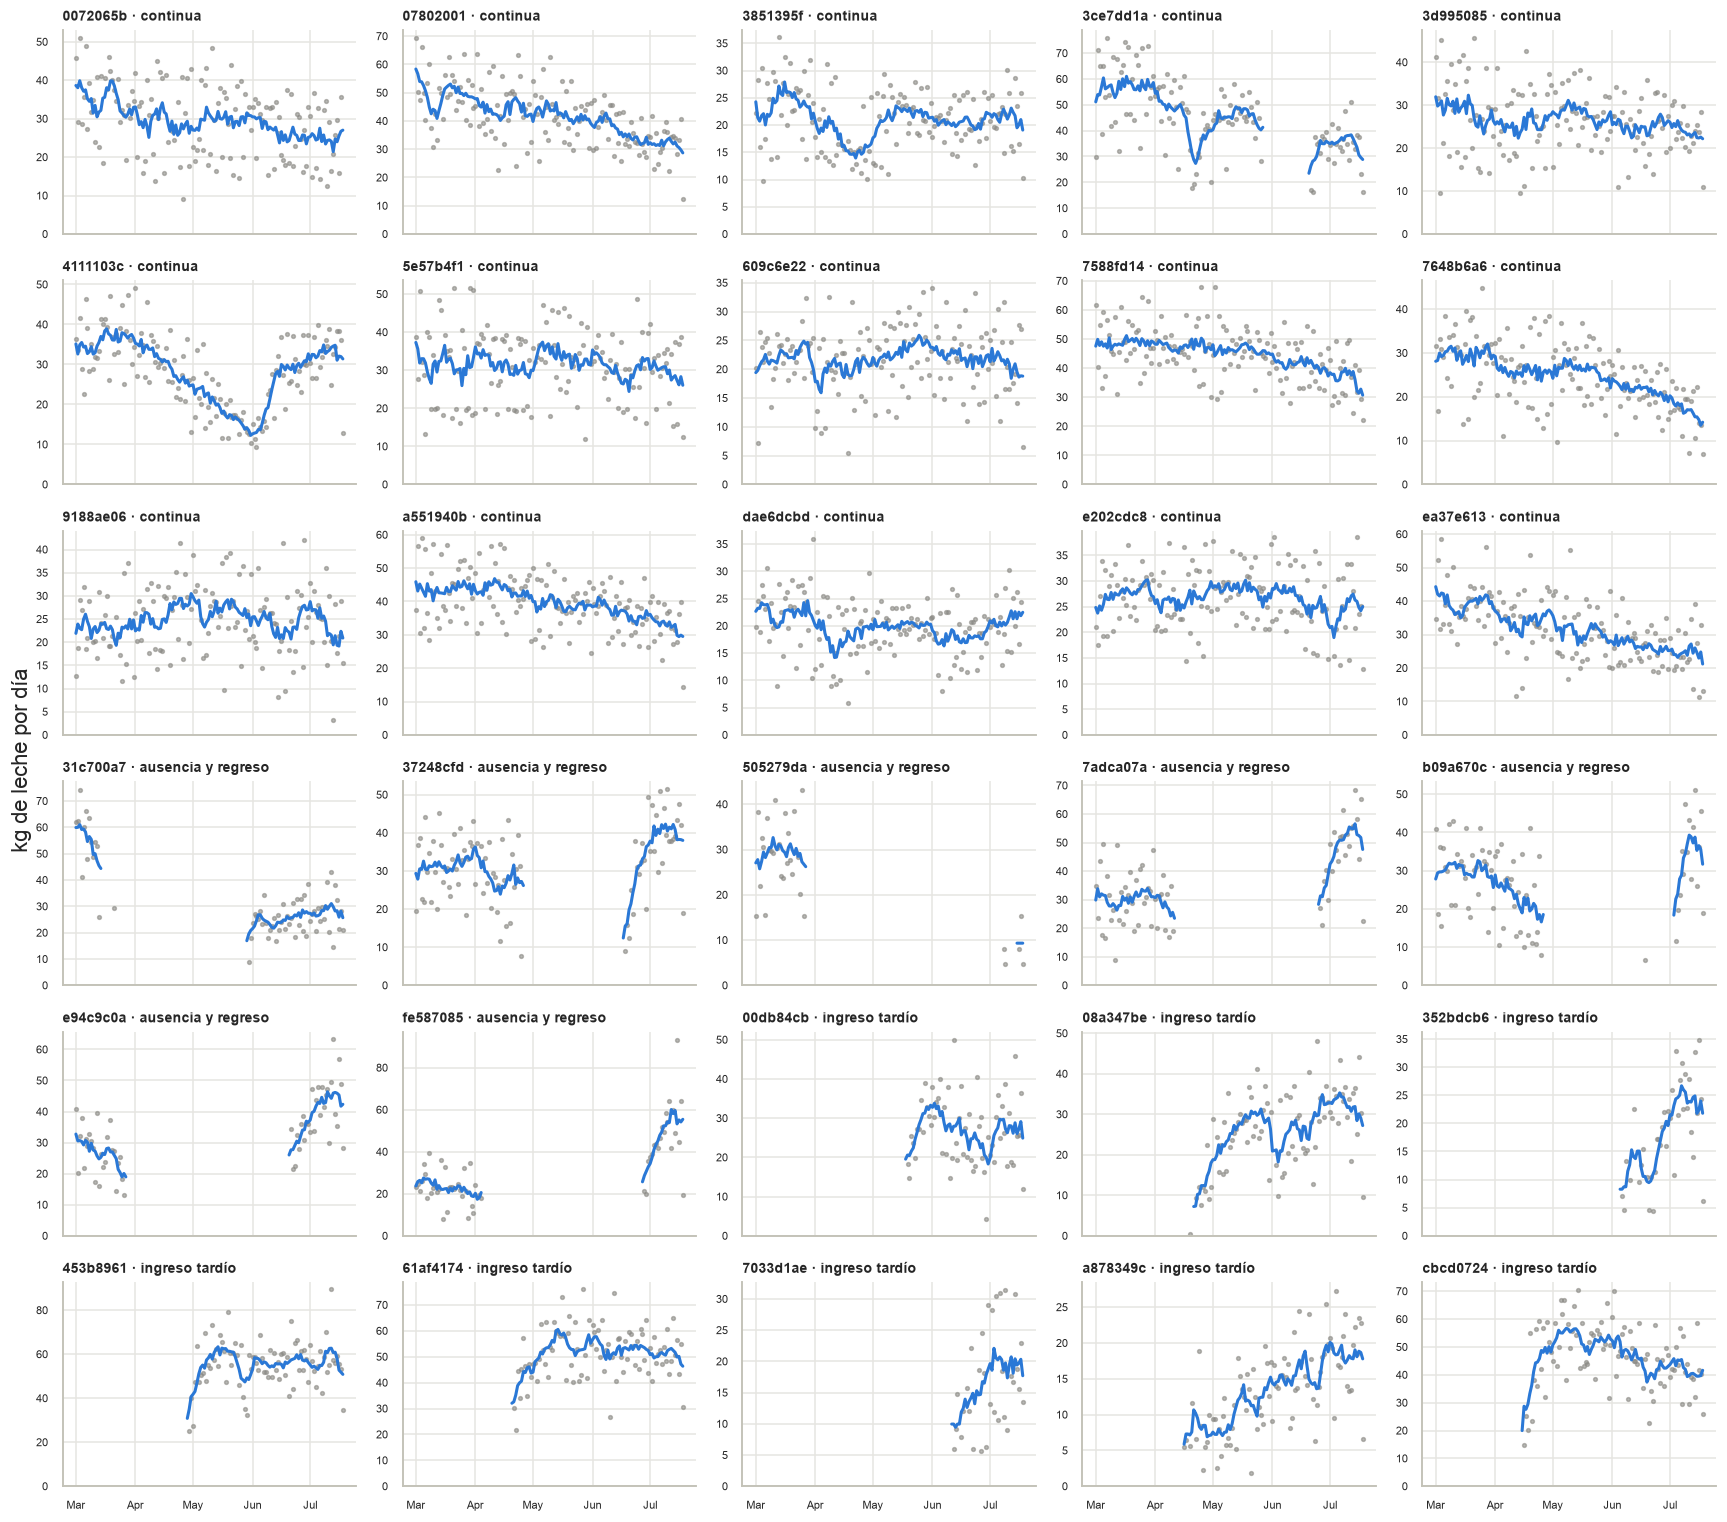

In [20]:
fig, axes = plt.subplots(6, 5, figsize=(16, 14), sharex=True)
for ax, (vaca, fila) in zip(axes.flat, resumen_vacas.iterrows()):
    kg, suave = serie_diaria(vaca)
    ax.scatter(kg.index, kg.values, s=6, color=GRIS, alpha=0.6)
    ax.plot(suave.index, suave.values, color=AZUL, linewidth=2)
    ax.set_title(f"{vaca} · {fila['grupo']}", fontsize=9)
    ax.set_ylim(0, None)
    ax.tick_params(labelsize=7)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
for ax in axes.flat[len(resumen_vacas):]:
    ax.axis("off")
fig.supylabel("kg de leche por día")
plt.tight_layout()
plt.show()

### 5.2 Vacas que se ausentan y regresan

Las zonas naranjas son los días sin ningún ordeño. Se muestran las vacas que pasaron más de 40 días sin ordeñarse.

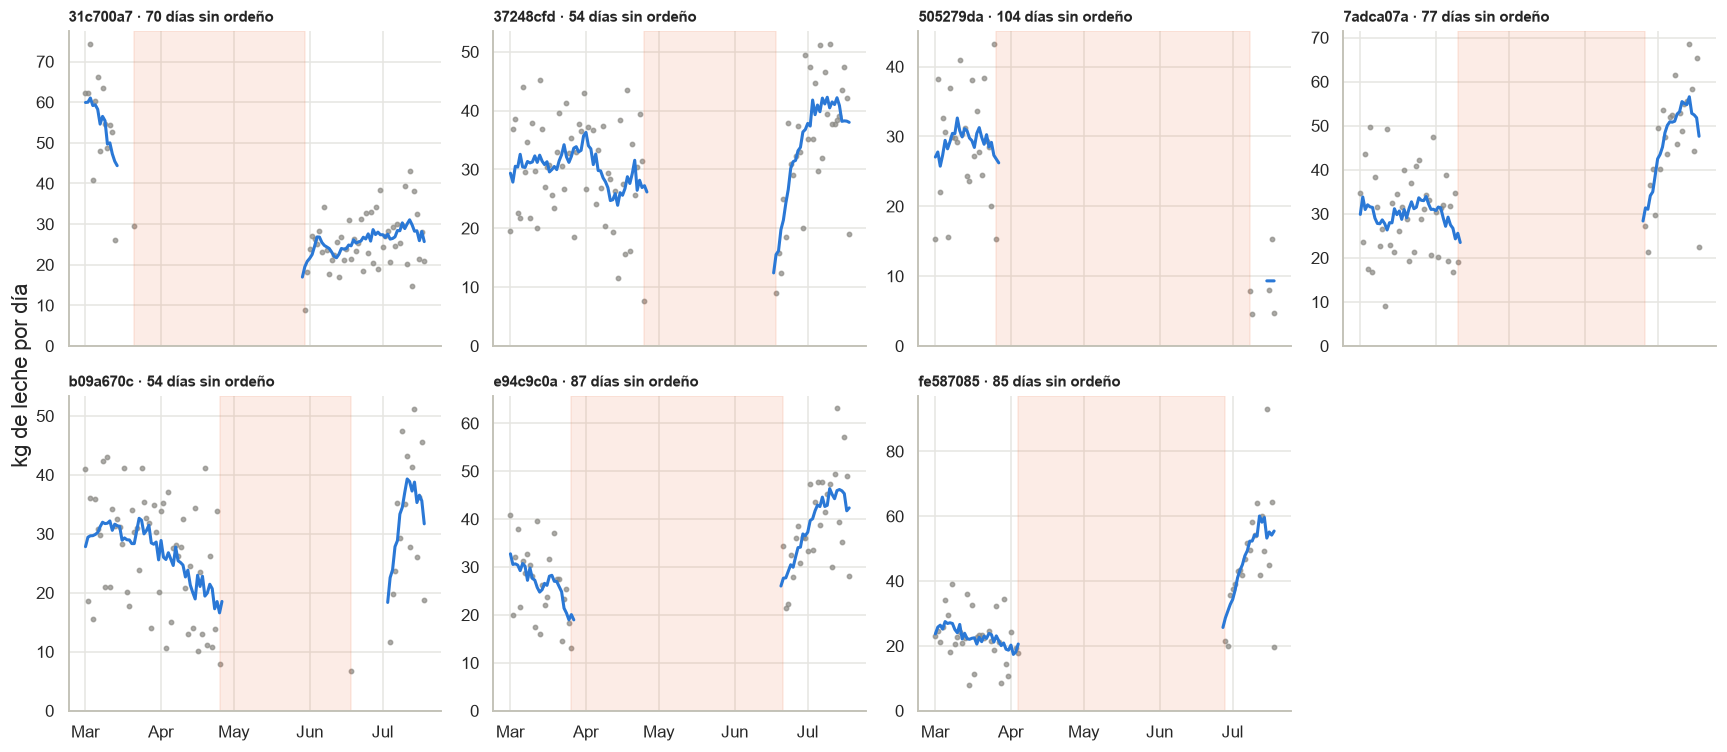

,dias_ausente,dias_tras_regresar,kg_primeros_3_dias,kg_pico_7d,dias_hasta_el_pico
vaca,,,,,
31c700a7,70,50,17.0,31.0,43
37248cfd,54,31,12.0,42.0,21
505279da,104,5,7.0,9.0,7
7adca07a,77,23,28.0,57.0,18
b09a670c,54,16,13.0,39.0,23
e94c9c0a,87,28,26.0,46.0,19
fe587085,85,21,26.0,60.0,14


In [21]:
ausentes = diaria[diaria["dias_sin_ordeño"] > 40][["id_vaca", "fecha", "dias_sin_ordeño"]]

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
for ax, (vaca, regreso, dias) in zip(axes.flat, ausentes.itertuples(index=False)):
    kg, suave = serie_diaria(vaca)
    ax.scatter(kg.index, kg.values, s=8, color=GRIS, alpha=0.7)
    ax.plot(suave.index, suave.values, color=AZUL, linewidth=2)
    ax.axvspan(regreso - pd.Timedelta(days=int(dias)), regreso, color=NARANJA, alpha=0.12)
    ax.set_title(f"{vaca} · {int(dias)} días sin ordeño", fontsize=10)
    ax.set_ylim(0, None)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
for ax in axes.flat[len(ausentes):]:
    ax.axis("off")
fig.supylabel("kg de leche por día")
plt.tight_layout()
plt.show()

# Que tanto sube la produccion despues de regresar
filas = []
for vaca, regreso, dias in ausentes.itertuples(index=False):
    despues = diaria[(diaria["id_vaca"] == vaca) & (diaria["fecha"] >= regreso)]
    suave = serie_diaria(vaca)[1][regreso:]
    filas.append({
        "vaca": vaca,
        "dias_ausente": int(dias),
        "dias_tras_regresar": len(despues),
        "kg_primeros_3_dias": despues["kg"].head(3).mean(),
        "kg_pico_7d": suave.max(),
        "dias_hasta_el_pico": (suave.idxmax() - regreso).days,
    })
pd.DataFrame(filas).set_index("vaca").round(0)

**Observaciones:**
- **La curva de lactancia sí se ve en los datos**, en tres comportamientos:
  - **Vacas continuas (15):** producción estable o a la baja durante los cuatro meses. La pendiente mediana es de unos −2 kg por día cada mes; 9 bajan más de 1 kg/mes y ninguna sube más de 1. Es la fase descendente de la curva (mitad o final de lactancia).
  - **Vacas que se ausentan y regresan (7):** pasan entre 54 y 104 días sin ordeño, lo que coincide con un periodo de secado. Al volver producen poco (12 a 28 kg los primeros 3 días) y en 14 a 23 días llegan a un pico de 39 a 60 kg. Es la fase ascendente tras un parto. Dos casos no siguen el patrón: `31c700a7` regresa a una producción mucho menor que la de antes (de ~55 a ~31 kg) y `505279da` solo tiene 5 días tras regresar, con unos 9 kg.
  - **Ingresos tardíos (8):** aparecen entre el 16 de abril y el 12 de junio con producción baja. Seis llegan al pico en 14 a 31 días, como una vaca recién parida; dos (`08a347be` y `a878349c`) suben mucho más despacio, hasta unos 76 a 78 días.
- **Los puntos grises son muy dispersos** porque la producción del día depende de cuántas veces vino la vaca: la mediana es 15.5 kg con un ordeño en el día, 27.9 con dos y 38.6 con tres. Por eso la línea azul (promedio de 7 días) es más confiable que un día suelto.
- **Hay caídas que no son parte de la curva:** `4111103c` baja de unos 38 kg a unos 12 kg entre abril y junio y luego se recupera, y `3851395f` tiene una caída parecida en abril y mayo. Pueden ser eventos de salud, de manejo o de clima; vale la pena preguntarlo al socio formador, porque son el tipo de cambio que el proyecto quiere detectar.
- **Límites:** solo hay 140 días de una lactancia de unos 305, no hay fecha de parto, y no se puede distinguir si una vaca que aparece tarde es nueva en el robot o está recién parida. La etapa de lactancia solo se puede inferir, no leer directamente.
- **Para el modelo:** la etapa cambia cuánto debe producir una vaca. 10 kg en un día es normal para una vaca que acaba de regresar y bajo para una en pico. Conviene usar variables como los días desde el regreso o ingreso, la tendencia de los últimos 7 días, o comparar cada ordeño contra la producción esperada de esa vaca.

## 6. Patrones y distribuciones

Primero se ven las distribuciones de las variables principales, después cómo se usan las máquinas y al final se compara la producción entre máquinas, cuartos y vacas.

In [22]:
# Variables auxiliares para las graficas de esta seccion (no se guardan en disco)
sesiones = df.drop_duplicates().copy()
hora_texto = (sesiones["main_hora_de_inicio"]
              .str.replace("a. m.", "AM", regex=False)
              .str.replace("p. m.", "PM", regex=False))
sesiones["inicio"] = pd.to_datetime(hora_texto, format="%d/%m/%Y %I:%M %p")

partes = sesiones["main_duracion_mm_ss"].str.split(":", expand=True).astype(int)
sesiones["duracion_seg"] = partes[0] * 60 + partes[1]
sesiones["duracion_min"] = sesiones["duracion_seg"] / 60
sesiones["fin"] = sesiones["inicio"] + pd.to_timedelta(sesiones["duracion_seg"], unit="s")
sesiones["fecha"] = sesiones["inicio"].dt.normalize()
sesiones["hora"] = sesiones["inicio"].dt.hour

# Horas desde el ordeño anterior de la misma vaca (solo entre ordeños)
sesiones = sesiones.sort_values(["id_vaca", "inicio"])
es_ordeno = sesiones["main_accion"] == "Ordeño"
sesiones.loc[es_ordeno, "horas_desde_anterior"] = (
    sesiones[es_ordeno].groupby("id_vaca")["inicio"].diff().dt.total_seconds() / 3600
)
ordenos_ses = sesiones[es_ordeno].copy()

# Un color fijo por maquina en todas las graficas
maquinas = sorted(sesiones["misc_eo_po"].unique())
color_maquina = dict(zip(maquinas, [AZUL, NARANJA, AQUA]))
print(f"Ordeños: {len(ordenos_ses):,} | Máquinas: {maquinas}")

Ordeños: 7,016 | Máquinas: ['7063e4b1', '86696b37', 'b96e85be']


### 6.1 Distribuciones

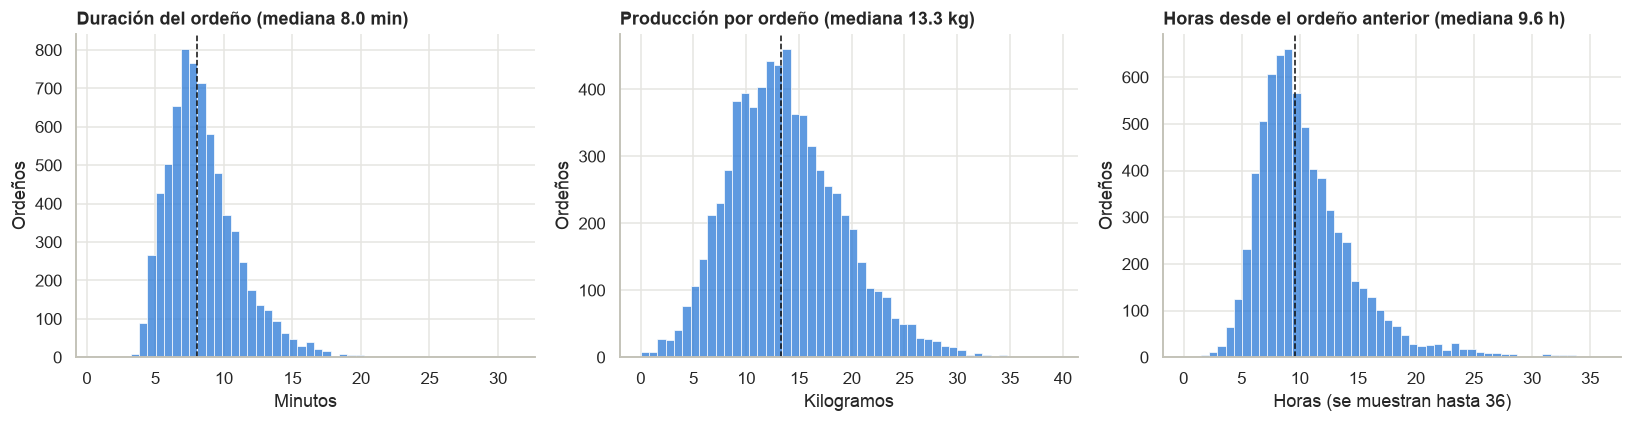

Intervalos de más de 36 h entre ordeños: 26


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(ordenos_ses["duracion_min"], bins=50, color=AZUL, ax=axes[0])
axes[0].axvline(ordenos_ses["duracion_min"].median(), color="#0b0b0b", linestyle="--", linewidth=1)
axes[0].set_title(f"Duración del ordeño (mediana {ordenos_ses['duracion_min'].median():.1f} min)")
axes[0].set_xlabel("Minutos")

sns.histplot(ordenos_ses["main_produccion_kg"], bins=50, color=AZUL, ax=axes[1])
axes[1].axvline(ordenos_ses["main_produccion_kg"].median(), color="#0b0b0b", linestyle="--", linewidth=1)
axes[1].set_title(f"Producción por ordeño (mediana {ordenos_ses['main_produccion_kg'].median():.1f} kg)")
axes[1].set_xlabel("Kilogramos")

intervalo = ordenos_ses["horas_desde_anterior"].dropna()
sns.histplot(intervalo[intervalo <= 36], bins=50, color=AZUL, ax=axes[2])
axes[2].axvline(intervalo.median(), color="#0b0b0b", linestyle="--", linewidth=1)
axes[2].set_title(f"Horas desde el ordeño anterior (mediana {intervalo.median():.1f} h)")
axes[2].set_xlabel("Horas (se muestran hasta 36)")

for ax in axes:
    ax.set_ylabel("Ordeños")
plt.tight_layout()
plt.show()

print(f"Intervalos de más de 36 h entre ordeños: {(intervalo > 36).sum()}")

**Observaciones:**
- Las tres variables son asimétricas a la derecha. La mitad central de los ordeños dura entre 6.7 y 9.8 min, produce entre 9.9 y 17.1 kg y ocurre entre 7.7 y 12.5 h después del anterior.
- Las colas largas son poco frecuentes pero existen: ordeños de más de 15 min (el más largo, 31 min), 26 intervalos de más de 36 h entre ordeños de una misma vaca y 4 ordeños con 0 kg.
- El intervalo entre ordeños tiene un pequeño repunte cerca de las 22–24 h, posiblemente vacas que se saltaron un ordeño.

### 6.2 Uso de las máquinas

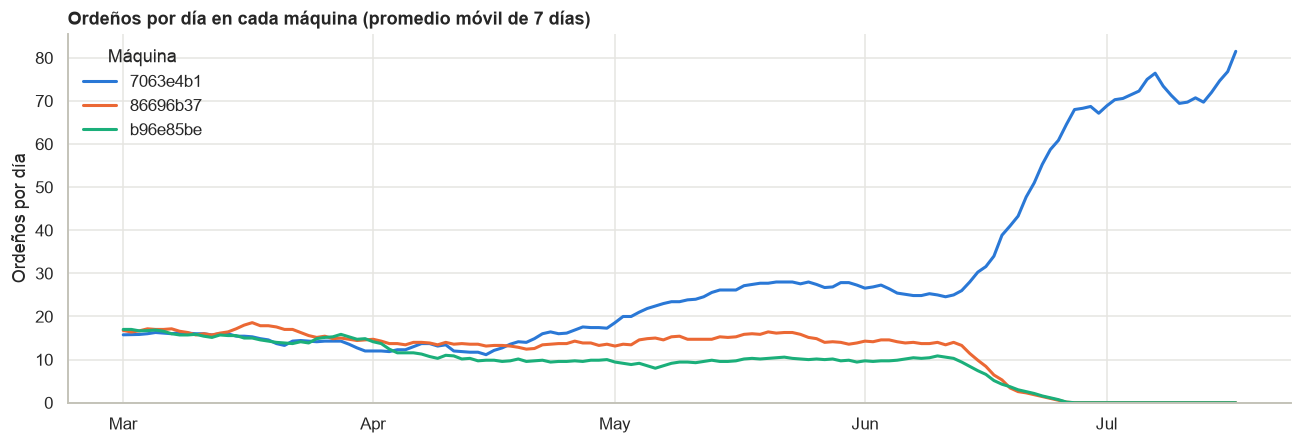

Vacas distintas por semana en cada máquina (primera y ultima semanas incompletas):


misc_eo_po,7063e4b1,86696b37,b96e85be
2025-02-24,9,6,7
2025-03-17,9,7,6
2025-04-07,8,6,4
2025-04-28,9,7,4
2025-05-19,10,7,4
2025-06-09,13,6,4
2025-06-30,30,0,0


In [24]:
# Ordeños por dia en cada maquina (se quita el ultimo dia, que esta incompleto)
dias_completos = pd.date_range(sesiones["fecha"].min(), sesiones["fecha"].max())[:-1]
por_dia = (ordenos_ses.groupby(["fecha", "misc_eo_po"]).size().unstack(fill_value=0)
           .reindex(index=dias_completos, columns=maquinas, fill_value=0))

fig, ax = plt.subplots(figsize=(12, 4.2))
for maquina in maquinas:
    ax.plot(por_dia.index, por_dia[maquina].rolling(7, min_periods=3, center=True).mean(),
            color=color_maquina[maquina], linewidth=2, label=maquina)
ax.set_title("Ordeños por día en cada máquina (promedio móvil de 7 días)")
ax.set_ylabel("Ordeños por día")
ax.set_ylim(0, None)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(title="Máquina", frameon=False)
plt.tight_layout()
plt.show()

print("Vacas distintas por semana en cada máquina (primera y ultima semanas incompletas):")
por_semana = (ordenos_ses.groupby([ordenos_ses["inicio"].dt.to_period("W").dt.start_time, "misc_eo_po"])["id_vaca"]
              .nunique().unstack(fill_value=0))
por_semana.index = por_semana.index.date
por_semana.iloc[::3]

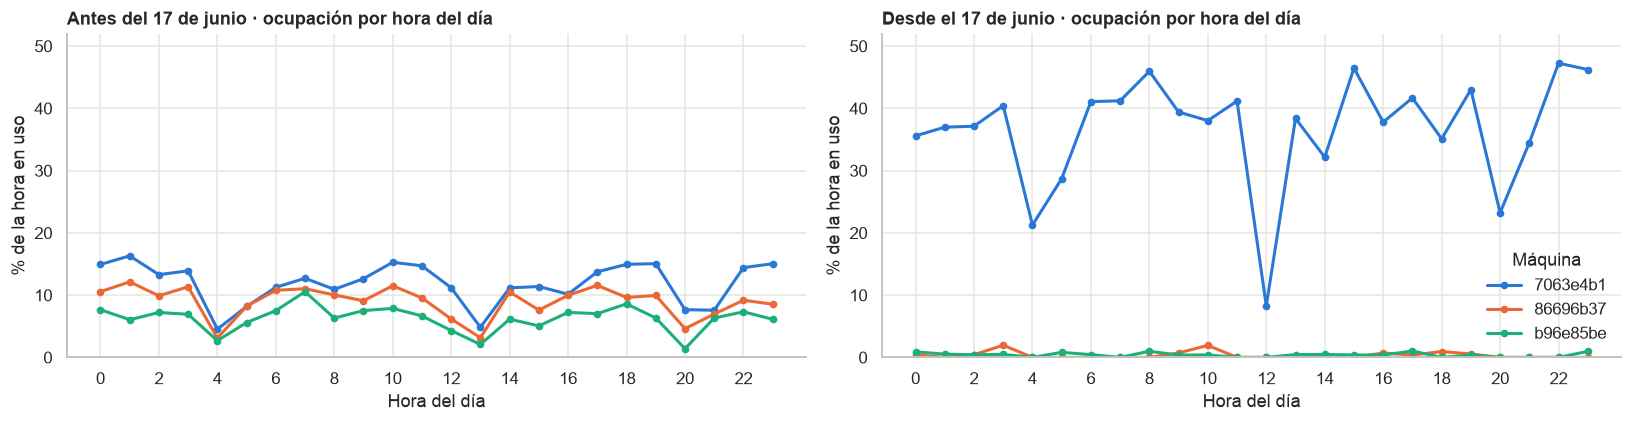

In [25]:
# Desde esta fecha casi todos los ordeños pasan a una sola maquina (ver la grafica anterior)
cambio = pd.Timestamp("2025-06-17")
antes = ordenos_ses[ordenos_ses["fecha"] < cambio]
despues = ordenos_ses[ordenos_ses["fecha"] >= cambio]
dias_antes = (cambio - sesiones["fecha"].min()).days
dias_despues = (sesiones["fecha"].max() - cambio).days + 1


def ocupacion_por_hora(datos, dias):
    """% de cada hora del dia que la maquina estuvo ordeñando (cada ordeño se asigna a su hora de inicio)."""
    segundos = (datos.groupby(["hora", "misc_eo_po"])["duracion_seg"].sum().unstack(fill_value=0)
                .reindex(index=range(24), columns=maquinas, fill_value=0))
    return segundos / dias / 3600 * 100


ocupaciones = {"Antes del 17 de junio": ocupacion_por_hora(antes, dias_antes),
               "Desde el 17 de junio": ocupacion_por_hora(despues, dias_despues)}
limite = max(o.to_numpy().max() for o in ocupaciones.values()) * 1.1   # misma escala en los dos paneles

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, (titulo, ocupacion) in zip(axes, ocupaciones.items()):
    for maquina in maquinas:
        ax.plot(ocupacion.index, ocupacion[maquina], color=color_maquina[maquina], linewidth=2, marker="o", markersize=4, label=maquina)
    ax.set_title(f"{titulo} · ocupación por hora del día")
    ax.set_xlabel("Hora del día")
    ax.set_xticks(range(0, 24, 2))
    ax.set_ylim(0, limite)
    ax.set_ylabel("% de la hora en uso")
axes[1].legend(title="Máquina", frameon=False)
plt.tight_layout()
plt.show()

In [26]:
# Tiempo libre de la maquina entre una vaca y la siguiente (relevos entre vacas distintas)
por_maquina = ordenos_ses.sort_values(["misc_eo_po", "inicio", "fin"]).copy()
agrupado = por_maquina.groupby("misc_eo_po")
por_maquina["vaca_anterior"] = agrupado["id_vaca"].shift()
por_maquina["hueco_min"] = (por_maquina["inicio"] - agrupado["fin"].shift()).dt.total_seconds() / 60

relevos = por_maquina[por_maquina["vaca_anterior"].notna() & (por_maquina["vaca_anterior"] != por_maquina["id_vaca"])].copy()
relevos["hueco_min"] = relevos["hueco_min"].clip(lower=0)   # la hora de inicio solo trae minutos: hay traslapes de hasta 0.5 min
relevos["periodo"] = np.where(relevos["fecha"] < cambio, "antes del 17 jun", "desde el 17 jun")

filas = []
for periodo, datos, dias in [("antes del 17 jun", antes, dias_antes), ("desde el 17 jun", despues, dias_despues)]:
    for maquina in maquinas:
        ordenos_m = datos[datos["misc_eo_po"] == maquina]
        relevos_m = relevos[(relevos["periodo"] == periodo) & (relevos["misc_eo_po"] == maquina)]
        filas.append({
            "periodo": periodo,
            "máquina": maquina,
            "ordeños_por_día": len(ordenos_m) / dias,
            "vacas": ordenos_m["id_vaca"].nunique(),
            "ocupación_%": ordenos_m["duracion_seg"].sum() / dias / 86400 * 100,
            "relevos_pegados_%": (relevos_m["hueco_min"] <= 2).mean() * 100 if len(relevos_m) else np.nan,
            "hueco_mediano_min": relevos_m["hueco_min"].median(),
        })
uso = pd.DataFrame(filas).set_index(["periodo", "máquina"]).round(1)
uso

ordeños_por_día  vacas  ocupación_%  relevos_pegados_%  hueco_mediano_min
periodo          máquina                                                                            
antes del 17 jun 7063e4b1             19.3     26         11.9               14.1               38.1
                 86696b37             14.8      8          9.0                7.9               65.0
                 b96e85be             11.5      7          6.3                7.3               82.0
desde el 17 jun  7063e4b1             64.2     34         36.7               45.4                5.1
                 86696b37              0.6      1          0.3                NaN                NaN
                 b96e85be              0.7      1          0.4                NaN                NaN

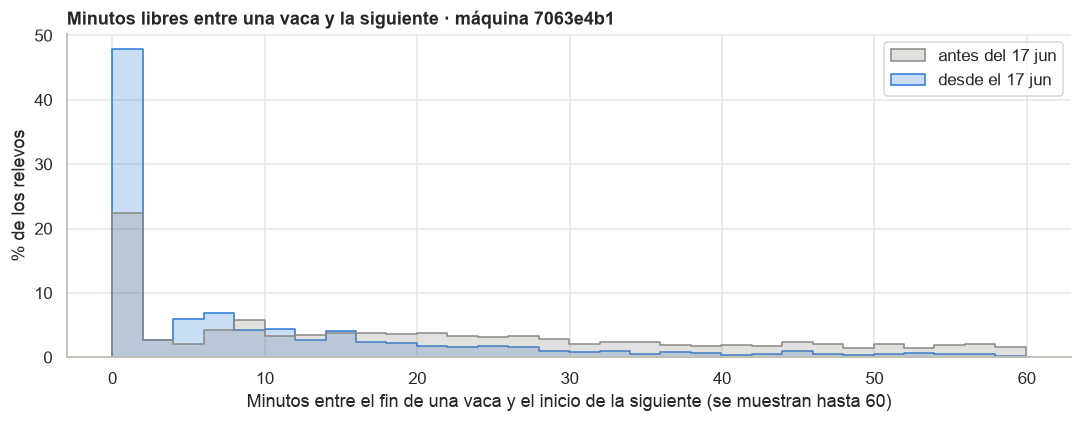

Relevos con más de 60 min libres: {'antes del 17 jun': 37.4, 'desde el 17 jun': 5.2} (% de cada periodo)


In [27]:
# Distribucion del tiempo libre en la maquina que concentra los ordeños desde el 17 de junio
principal = despues["misc_eo_po"].value_counts().idxmax()
hueco = relevos[(relevos["misc_eo_po"] == principal)]

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=hueco[hueco["hueco_min"] <= 60], x="hueco_min", hue="periodo", bins=30, stat="percent",
             common_norm=False, element="step", palette={"antes del 17 jun": GRIS, "desde el 17 jun": color_maquina[principal]}, ax=ax)
ax.set_title(f"Minutos libres entre una vaca y la siguiente · máquina {principal}")
ax.set_xlabel("Minutos entre el fin de una vaca y el inicio de la siguiente (se muestran hasta 60)")
ax.set_ylabel("% de los relevos")
ax.get_legend().set_title("")
plt.tight_layout()
plt.show()

print(f"Relevos con más de 60 min libres: {(hueco['hueco_min'] > 60).groupby(hueco['periodo']).mean().mul(100).round(1).to_dict()} (% de cada periodo)")

**Observaciones:**
- **El uso de las máquinas cambió a mediados de junio.** Hasta entonces las tres se repartían el trabajo, con entre 11 y 19 ordeños diarios cada una al inicio. Entre el 12 y el 23 de junio las máquinas `86696b37` y `b96e85be` dejan de usarse (desde ahí casi cero ordeños por día) y todo el hato pasa a `7063e4b1`. El 17 de junio es un corte aproximado de esa transición.
- **Efecto en la máquina `7063e4b1`:**

| | Antes del 17 jun | Desde el 17 jun |
| :-- | --: | --: |
| Ordeños por día | 19.3 | 64.2 |
| Vacas que la usan | 26 | 34 |
| Ocupación del día | 11.9 % | 36.7 % |
| Relevos a 2 min o menos del fin de la vaca anterior | 14.1 % | 45.4 % |
| Tiempo libre mediano entre vacas | 38 min | 5 min |
| Relevos con más de 60 min libres | 37.4 % | 5.2 % |

- **Esta es la señal de cola más cercana que tienen los datos.** Antes del cambio la máquina pasaba la mayor parte del tiempo libre; después, casi la mitad de las vacas entran apenas termina la anterior. Sigue siendo una medida indirecta: no hay hora de llegada, así que un relevo pegado no demuestra que la vaca haya esperado.
- **El análisis de colas debe separar los dos periodos.** Desde el 17 de junio hay solo 32 días con una sola máquina; mezclarlos con los 108 días anteriores diluye la señal. Por la misma razón, comparar máquinas entre sí o contar ordeños por máquina de todo el periodo da conclusiones engañosas.
- **Horas de menor uso:** en las tres máquinas y en ambos periodos hay caídas cerca de las 4:00, las 12:00–13:00 y las 20:00. Parecen paradas programadas (por ejemplo limpieza); queda por confirmar con el CAETEC. Desde el 17 de junio, `7063e4b1` baja a 21 % de uso a las 4:00, a 8 % a las 12:00 y a 23 % a las 20:00, contra 35–47 % el resto del día.
- **Pregunta pendiente:** por qué el hato se movió a una sola máquina (falla, mantenimiento o decisión de manejo).

### 6.3 Comparativa de producción

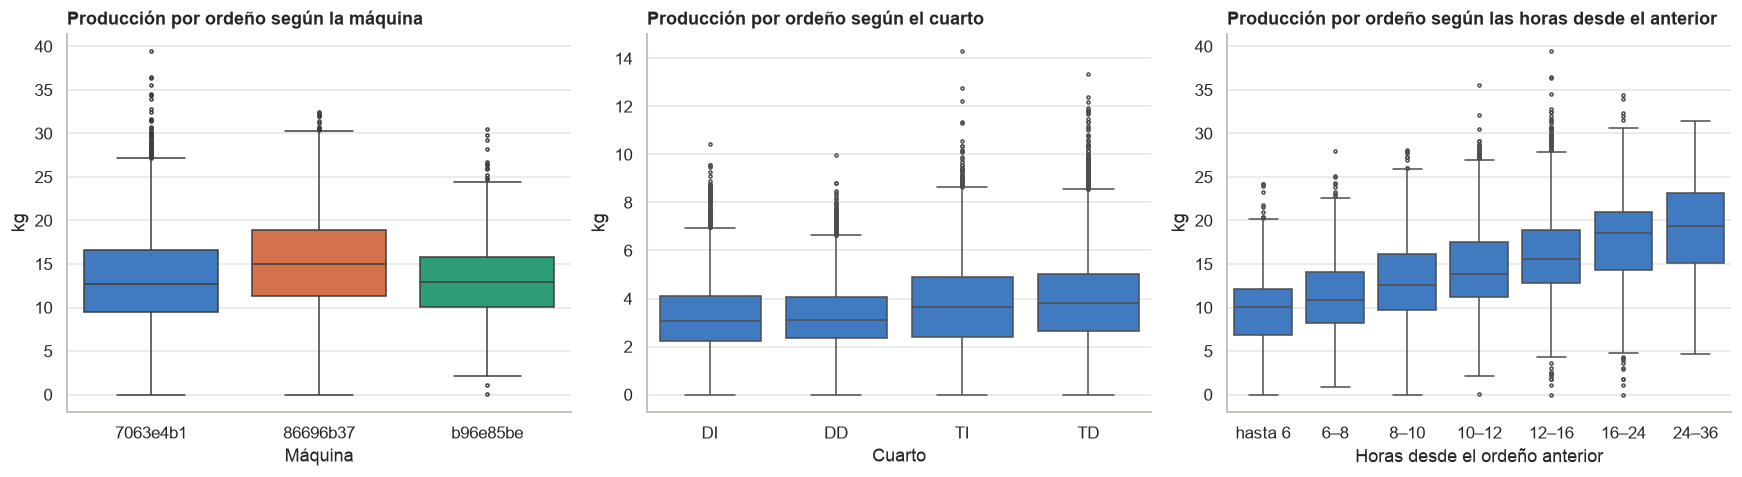

Medianas por cuarto (kg):
producciones_kg_di    3.08
producciones_kg_dd    3.11
producciones_kg_ti    3.63
producciones_kg_td    3.80

Duración mediana (min) según las horas desde el ordeño anterior:
horas_desde_anterior
hasta 6    7.7
6–8        7.7
8–10       7.8
10–12      8.0
12–16      8.3
16–24      8.6
24–36      8.8


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Por maquina
sns.boxplot(data=ordenos_ses, x="misc_eo_po", y="main_produccion_kg", hue="misc_eo_po", order=maquinas,
            palette=color_maquina, legend=False, fliersize=2, ax=axes[0])
axes[0].set_title("Producción por ordeño según la máquina")
axes[0].set_xlabel("Máquina")

# Por cuarto de la ubre
por_cuarto = (ordenos_ses[[f"producciones_kg_{c}" for c in ["di", "dd", "ti", "td"]]]
              .rename(columns=lambda c: c[-2:].upper())
              .melt(var_name="cuarto", value_name="kg"))
sns.boxplot(data=por_cuarto, x="cuarto", y="kg", color=AZUL, fliersize=2, ax=axes[1])
axes[1].set_title("Producción por ordeño según el cuarto")
axes[1].set_xlabel("Cuarto")

# Segun cuanto tiempo paso desde el ordeño anterior
rangos = pd.cut(ordenos_ses["horas_desde_anterior"], [0, 6, 8, 10, 12, 16, 24, 36],
                labels=["hasta 6", "6–8", "8–10", "10–12", "12–16", "16–24", "24–36"])
sns.boxplot(x=rangos, y=ordenos_ses["main_produccion_kg"], color=AZUL, fliersize=2, ax=axes[2])
axes[2].set_title("Producción por ordeño según las horas desde el anterior")
axes[2].set_xlabel("Horas desde el ordeño anterior")

for ax in axes:
    ax.set_ylabel("kg")
plt.tight_layout()
plt.show()

print("Medianas por cuarto (kg):")
print(ordenos_ses[[f"producciones_kg_{c}" for c in ["di", "dd", "ti", "td"]]].median().round(2).to_string())
print("\nDuración mediana (min) según las horas desde el ordeño anterior:")
print(ordenos_ses.groupby(rangos, observed=True)["duracion_min"].median().round(1).to_string())

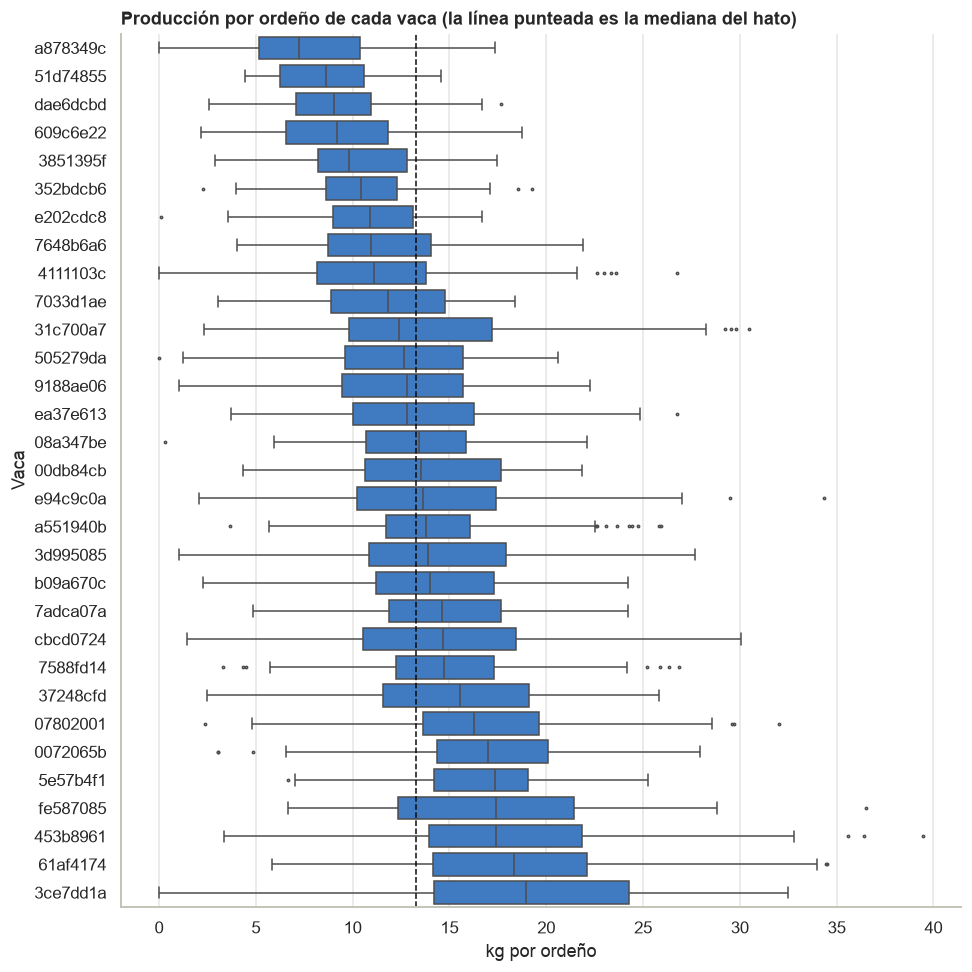

Vacas mostradas: 31 | mediana más baja: 7.2 kg | más alta: 19.0 kg


In [29]:
# Producción por ordeño de cada vaca (vacas con al menos 30 ordeños), de menor a mayor mediana
por_vaca = ordenos_ses.groupby("id_vaca")["main_produccion_kg"]
orden_vacas = por_vaca.median()[por_vaca.size() >= 30].sort_values().index

fig, ax = plt.subplots(figsize=(9, 9))
sns.boxplot(data=ordenos_ses[ordenos_ses["id_vaca"].isin(orden_vacas)], y="id_vaca", x="main_produccion_kg",
            order=orden_vacas, color=AZUL, fliersize=1.5, orient="h", ax=ax)
ax.axvline(ordenos_ses["main_produccion_kg"].median(), color="#0b0b0b", linestyle="--", linewidth=1)
ax.set_title("Producción por ordeño de cada vaca (la línea punteada es la mediana del hato)")
ax.set_xlabel("kg por ordeño")
ax.set_ylabel("Vaca")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print(f"Vacas mostradas: {len(orden_vacas)} | mediana más baja: {por_vaca.median()[orden_vacas].min():.1f} kg | más alta: {por_vaca.median()[orden_vacas].max():.1f} kg")

**Observaciones:**
- **Por máquina:** las medianas son 12.7, 15.1 y 12.9 kg por ordeño. No se debe leer como un efecto de la máquina: cada una atendió vacas distintas en momentos distintos, y las diferencias entre vacas son mucho mayores.
- **Por cuarto:** los traseros producen más. Las medianas son 3.63 kg (TI) y 3.80 kg (TD), contra 3.08 kg (DI) y 3.11 kg (DD), alrededor de 20 % más.
- **Por intervalo:** la producción por ordeño sube de unos 10 kg cuando pasaron hasta 6 h desde el anterior a unos 19 kg cuando pasaron entre 24 y 36 h, pero la duración casi no cambia (de 7.7 a 8.8 min). Cada vaca ocupa la máquina unos 8 minutos sin importar cuánta leche dé, así que para la cola importa cuántas visitas hay y no cuánto produce cada una.
- **Por vaca:** la mediana por ordeño va de 7.2 a 19.0 kg, 2.6 veces entre la más baja y la más alta. Dentro de cada vaca también hay mucha variación, por el intervalo entre ordeños y por la etapa de lactancia (sección 5).
- **Para el modelo:** 8 kg es normal para una vaca de producción baja o con poco tiempo desde el ordeño anterior, y bajo para otra. Una comparación justa debe medir cada ordeño contra lo que esa vaca suele producir con un intervalo parecido.

## 7. ¿Hay problema de cola?

El dataset no trae la hora de llegada de cada vaca, así que no se puede medir cuánto esperó. Lo que sí se tiene es la hora de inicio y la duración de cada ordeño, y con eso el **tiempo que la máquina quedó libre entre una vaca y la siguiente**:

> tiempo libre = hora de inicio de la vaca siguiente − (hora de inicio + duración) de la vaca anterior

Si la siguiente vaca empieza a 2 minutos o menos de que termine la anterior, la máquina casi no descansó: puede haber una vaca esperando. A eso se le llama aquí **relevo pegado**, y una **racha** es una serie de vacas seguidas con relevos pegados.

Un relevo pegado por sí solo no prueba que haya cola: aunque las vacas llegaran al azar, algunas coincidirían con la anterior. Por eso cada resultado se compara contra una simulación de **llegadas al azar** con el mismo número de vacas por hora y las mismas duraciones de ordeño. Si lo observado se parece a la simulación, la congestión es la que produce la carga y no un problema especial. Si es mucho mayor, las vacas llegan en grupos.

Se analiza solo la máquina que concentra los ordeños desde el 17 de junio.

### 7.1 ¿Lo observado es más de lo que daría el azar?

In [30]:
# Desde el 17 de junio: ordeños de la maquina principal en orden de inicio
cola = ordenos_ses[ordenos_ses["misc_eo_po"] == principal].sort_values(["inicio", "fin"]).copy()
cola["hueco_min"] = ((cola["inicio"] - cola["fin"].shift()).dt.total_seconds() / 60).clip(lower=0)
cola["pegado"] = (cola["hueco_min"] <= 2) & (cola["id_vaca"] != cola["id_vaca"].shift())
cola = cola[cola["fecha"] >= cambio].copy()

# Vacas que llegan por hora del dia (se usa la hora de inicio de cada ordeño)
llegadas_por_hora = (cola.groupby("hora").size() / dias_despues).reindex(range(24), fill_value=0)


def simular_cola(llegadas_por_hora, duraciones, dias, semilla=0):
    """
        Simula una sola maquina con llegadas al azar (Poisson) segun las vacas por hora observadas
        y duraciones tomadas al azar de las observadas. Las vacas se atienden en orden de llegada.

        Args:
            llegadas_por_hora (Series): Vacas que llegan en promedio en cada hora del dia.
            duraciones (array): Duraciones de ordeño observadas, en minutos.
            dias (int): Dias a simular.
            semilla (int): Semilla del generador aleatorio.

        Returns:
            DataFrame: Una fila por vaca con llegada, inicio, fin, tiempo libre antes de ella y espera.
    """
    rng = np.random.default_rng(semilla)
    llegadas = np.sort(np.concatenate([
        d * 1440 + h * 60 + rng.uniform(0, 60, rng.poisson(llegadas_por_hora[h]))
        for d in range(dias) for h in range(24)
    ]))
    servicio = rng.choice(duraciones, size=len(llegadas))

    inicio = np.empty(len(llegadas))
    fin = np.empty(len(llegadas))
    libre = 0.0
    for i, (llegada, duracion) in enumerate(zip(llegadas, servicio)):
        inicio[i] = max(llegada, libre)
        fin[i] = inicio[i] + duracion
        libre = fin[i]

    sim = pd.DataFrame({"llegada": llegadas, "inicio": inicio, "fin": fin, "duracion_min": servicio})
    sim["hueco_min"] = sim["inicio"] - sim["fin"].shift()
    sim["espera_min"] = sim["inicio"] - sim["llegada"]
    sim["pegado"] = sim["hueco_min"] <= 2
    sim["hora"] = ((sim["inicio"] % 1440) // 60).astype(int)
    return sim.iloc[1:]


def tamanos_de_racha(pegado):
    """Cuantas vacas seguidas tiene cada racha (la racha empieza con una vaca que no estaba pegada a la anterior)."""
    pegado = pegado.reset_index(drop=True)
    return pegado.groupby((~pegado).cumsum()).size()


dias_sim = 2000
sim = simular_cola(llegadas_por_hora, cola["duracion_min"].to_numpy(), dias_sim)
rachas_obs = tamanos_de_racha(cola["pegado"])
rachas_sim = tamanos_de_racha(sim["pegado"])

comparacion = pd.DataFrame({
    "observado": {
        "Ocupación de la máquina (%)": cola["duracion_seg"].sum() / dias_despues / 86400 * 100,
        "Relevos pegados (%)": cola["pegado"].mean() * 100,
        "Vacas por racha (promedio)": rachas_obs.mean(),
        "Rachas de 5 vacas o más (%)": (rachas_obs >= 5).mean() * 100,
        "Espera promedio de una vaca (min)": np.nan,
        "Espera que superan 9 de cada 10 vacas (min)": np.nan,
        "Vacas que esperan más de 5 min (%)": np.nan,
        "Vacas que esperan más de 10 min (%)": np.nan,
    },
    "si llegaran al azar": {
        "Ocupación de la máquina (%)": sim["duracion_min"].sum() / (dias_sim * 1440) * 100,
        "Relevos pegados (%)": sim["pegado"].mean() * 100,
        "Vacas por racha (promedio)": rachas_sim.mean(),
        "Rachas de 5 vacas o más (%)": (rachas_sim >= 5).mean() * 100,
        "Espera promedio de una vaca (min)": sim["espera_min"].mean(),
        "Espera que superan 9 de cada 10 vacas (min)": sim["espera_min"].quantile(0.9),
        "Vacas que esperan más de 5 min (%)": (sim["espera_min"] > 5).mean() * 100,
        "Vacas que esperan más de 10 min (%)": (sim["espera_min"] > 10).mean() * 100,
    },
}).round(1)
comparacion.astype(object).fillna("no se puede medir")

,observado,si llegaran al azar
Ocupación de la máquina (%),36.7,36.6
Relevos pegados (%),45.4,43.6
Vacas por racha (promedio),1.8,1.8
Rachas de 5 vacas o más (%),5.2,5.3
Espera promedio de una vaca (min),no se puede medir,2.8
Espera que superan 9 de cada 10 vacas (min),no se puede medir,9.7
Vacas que esperan más de 5 min (%),no se puede medir,22.4
Vacas que esperan más de 10 min (%),no se puede medir,9.5


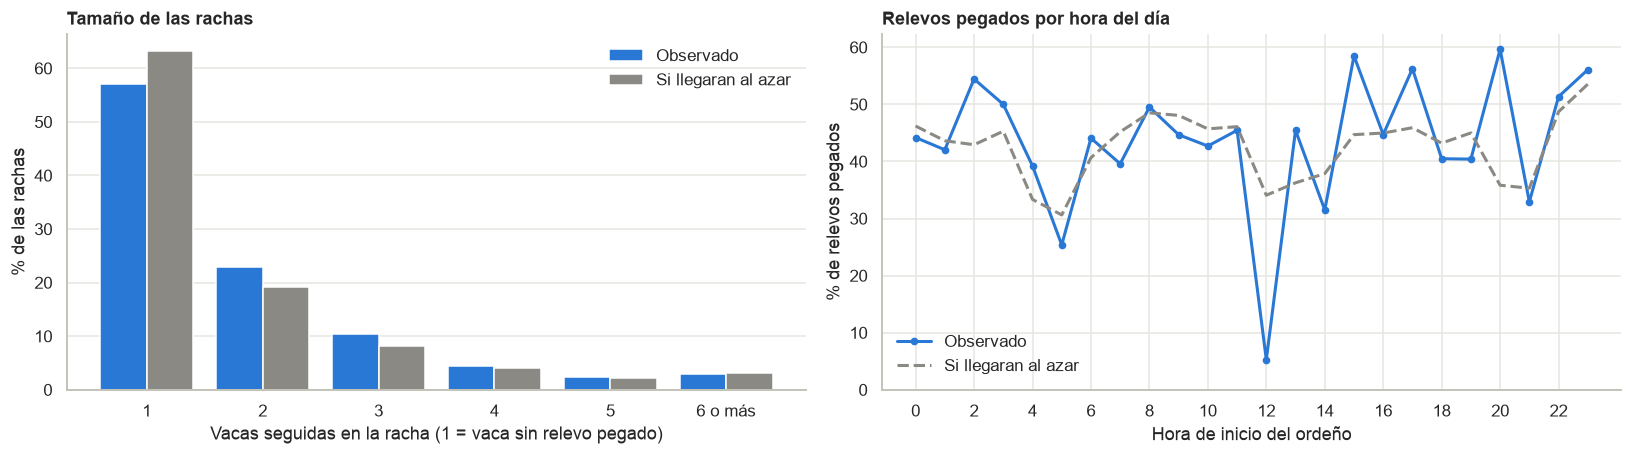

Horas donde lo observado se aleja más de lo esperado al azar (con al menos 50 ordeños):
      ordeños  observado_%  azar_%  diferencia
hora                                          
20         57           60      36          24
15        106           58      45          13
2          90           54      43          11
17         96           56      46          10


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))

# Cuantas vacas seguidas hay en cada racha
etiquetas = ["1", "2", "3", "4", "5", "6 o más"]
def distribucion(rachas):
    return [(rachas == k).mean() * 100 for k in range(1, 6)] + [(rachas >= 6).mean() * 100]
x = np.arange(len(etiquetas))
axes[0].bar(x - 0.2, distribucion(rachas_obs), width=0.4, color=color_maquina[principal], label="Observado")
axes[0].bar(x + 0.2, distribucion(rachas_sim), width=0.4, color=GRIS, label="Si llegaran al azar")
axes[0].set_xticks(x, etiquetas)
axes[0].set_xlabel("Vacas seguidas en la racha (1 = vaca sin relevo pegado)")
axes[0].set_ylabel("% de las rachas")
axes[0].set_title("Tamaño de las rachas")
axes[0].legend(frameon=False)
axes[0].grid(axis="x", visible=False)

# Relevos pegados segun la hora de inicio
pegados_obs = cola.groupby("hora")["pegado"].mean() * 100
pegados_sim = sim.groupby("hora")["pegado"].mean() * 100
axes[1].plot(pegados_obs.index, pegados_obs.values, color=color_maquina[principal], linewidth=2, marker="o", markersize=4, label="Observado")
axes[1].plot(pegados_sim.index, pegados_sim.values, color=GRIS, linewidth=2, linestyle="--", label="Si llegaran al azar")
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_xlabel("Hora de inicio del ordeño")
axes[1].set_ylabel("% de relevos pegados")
axes[1].set_ylim(0, None)
axes[1].set_title("Relevos pegados por hora del día")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

por_hora = pd.DataFrame({"ordeños": cola.groupby("hora").size(), "observado_%": pegados_obs, "azar_%": pegados_sim}).round(0)
print("Horas donde lo observado se aleja más de lo esperado al azar (con al menos 50 ordeños):")
print(por_hora[por_hora["ordeños"] >= 50].assign(diferencia=lambda t: t["observado_%"] - t["azar_%"])
      .sort_values("diferencia", key=abs, ascending=False).head(4).astype(int).to_string())

**Observaciones:**
- **Lo observado se parece mucho a lo que producirían llegadas al azar.** Relevos pegados: 45.4 % contra 43.6 %. Vacas por racha: 1.8 contra 1.8. Rachas de 5 vacas o más: 5.2 % contra 5.3 %. Con la máquina ocupada 36.7 % del tiempo, es normal que casi la mitad de los relevos sea pegado, así que ese porcentaje por sí solo no indica una cola anormal.
- **Las vacas llegan algo agrupadas.** Hay más rachas de 2 y 3 vacas y menos vacas solas (57 % contra 63 %) de lo que daría el azar, pero no hay más rachas largas.
- **Algunas horas se alejan de lo esperado.** A las 20:00 hay 60 % de relevos pegados contra 36 % esperado (57 ordeños); también a las 15:00 (58 % contra 45 %), las 2:00 (54 % contra 43 %) y las 17:00 (56 % contra 46 %). A las 12:00 casi no hay (5 %, solo 19 ordeños) porque la máquina está casi parada. Una explicación posible para las 20:00 es que las vacas se acumulan durante la parada de esa hora y salen una tras otra al reanudar; es una hipótesis, y con menos de 110 ordeños por hora las diferencias de 10 puntos pueden ser ruido.
- **Esperas estimadas (de la simulación, no medidas):** en promedio 2.8 min; 22 % de las vacas esperarían más de 5 min y 9.5 % más de 10 min; 9 de cada 10 esperarían menos de 9.7 min.

### 7.2 ¿Una duración larga provoca que el siguiente empiece pegado?

Una vaca que tarda más hace que más vacas lleguen mientras la máquina está ocupada, así que lo esperable es que después de un ordeño largo sea más probable un relevo pegado. Se revisa si pasa y si el ordeño incompleto, que dura más, empeora la cola.

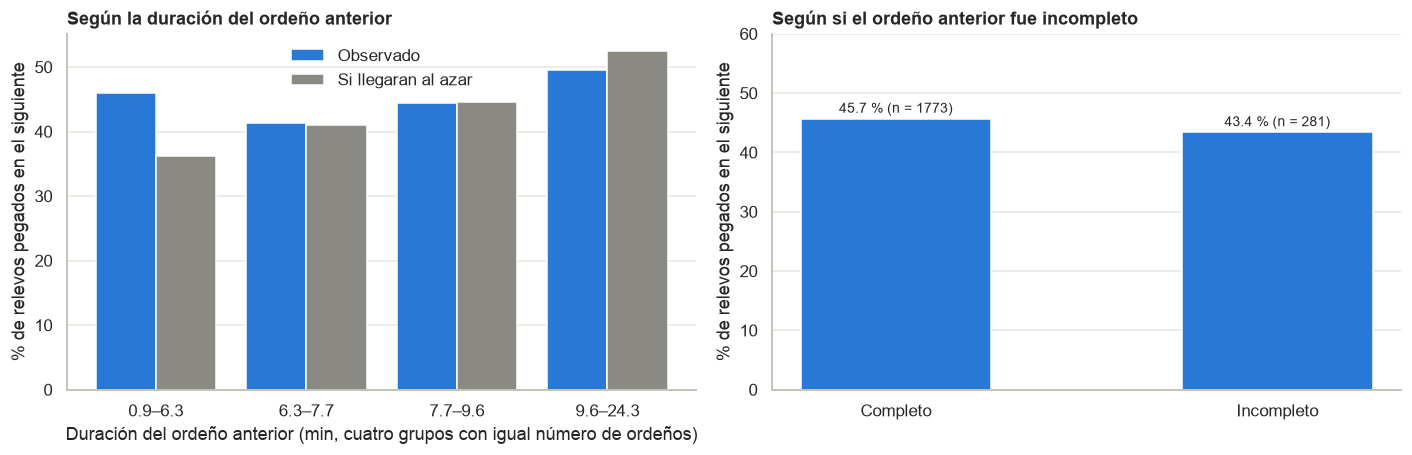

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

# Segun la duracion del ordeño anterior (mismos cortes en lo observado y en la simulacion)
bordes = cola["duracion_min"].quantile([0, 0.25, 0.5, 0.75, 1]).to_numpy()
nombres = [f"{bordes[i]:.1f}–{bordes[i + 1]:.1f}" for i in range(4)]
previa_obs = pd.cut(cola["duracion_min"].shift(), bordes, labels=nombres, include_lowest=True)
previa_sim = pd.cut(sim["duracion_min"].shift(), bordes, labels=nombres, include_lowest=True)
por_duracion = pd.DataFrame({
    "observado": cola.groupby(previa_obs, observed=True)["pegado"].mean() * 100,
    "azar": sim.groupby(previa_sim, observed=True)["pegado"].mean() * 100,
})
x = np.arange(4)
axes[0].bar(x - 0.2, por_duracion["observado"], width=0.4, color=color_maquina[principal], label="Observado")
axes[0].bar(x + 0.2, por_duracion["azar"], width=0.4, color=GRIS, label="Si llegaran al azar")
axes[0].set_xticks(x, nombres)
axes[0].set_xlabel("Duración del ordeño anterior (min, cuatro grupos con igual número de ordeños)")
axes[0].set_ylabel("% de relevos pegados en el siguiente")
axes[0].set_title("Según la duración del ordeño anterior")
axes[0].legend(frameon=False)
axes[0].grid(axis="x", visible=False)

# Segun si el ordeño anterior fue incompleto
anterior_incompleto = cola["estado_incompleto"].notna().shift(fill_value=False)
por_incompleto = cola.groupby(anterior_incompleto)["pegado"].agg(["mean", "size"])
axes[1].bar(["Completo", "Incompleto"], por_incompleto["mean"] * 100, color=color_maquina[principal], width=0.5)
for i, (media, n) in enumerate(zip(por_incompleto["mean"], por_incompleto["size"])):
    axes[1].text(i, media * 100 + 1, f"{media * 100:.1f} % (n = {n})", ha="center", fontsize=9)
axes[1].set_ylim(0, 60)
axes[1].set_ylabel("% de relevos pegados en el siguiente")
axes[1].set_title("Según si el ordeño anterior fue incompleto")
axes[1].grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

In [33]:
# Cuanto tiempo de maquina agregan los ordeños incompletos
incompleto = cola["estado_incompleto"].notna()
mediana_completo = cola.loc[~incompleto, "duracion_min"].median()
exceso = (cola.loc[incompleto, "duracion_min"] - mediana_completo).clip(lower=0).sum()
tiempo_ocupado = cola["duracion_min"].sum()

pd.Series({
    "Ordeños incompletos (%)": incompleto.mean() * 100,
    "Duración mediana de un ordeño completo (min)": mediana_completo,
    "Duración mediana de un ordeño incompleto (min)": cola.loc[incompleto, "duracion_min"].median(),
    "Minutos extra por día por los incompletos": exceso / dias_despues,
    "Parte del tiempo ocupado de la máquina (%)": exceso / tiempo_ocupado * 100,
    "Ocupación con la máquina como está (%)": tiempo_ocupado / (dias_despues * 1440) * 100,
    "Ocupación sin ese tiempo extra (%)": (tiempo_ocupado - exceso) / (dias_despues * 1440) * 100,
}, name="valor").round(1).to_frame()

,valor
Ordeños incompletos (%),13.7
Duración mediana de un ordeño completo (min),7.5
Duración mediana de un ordeño incompleto (min),10.0
Minutos extra por día por los incompletos,26.2
Parte del tiempo ocupado de la máquina (%),4.9
Ocupación con la máquina como está (%),36.7
Ocupación sin ese tiempo extra (%),34.9


**Observaciones:**
- **La duración del ordeño anterior influye menos de lo esperado.** Por grupos de duración, de menor a mayor, los relevos pegados son 46.0 %, 41.3 %, 44.5 % y 49.6 %, contra 36.2 %, 41.0 %, 44.6 % y 52.5 % si las vacas llegaran al azar. Los ordeños más cortos van seguidos de más relevos pegados de lo esperado.
- **Un ordeño incompleto no hace que el siguiente empiece pegado más seguido:** 43.4 % después de uno incompleto (281 casos) contra 45.7 % después de uno completo (1,773 casos).
- **Los ordeños incompletos agregan poco tiempo de máquina.** Son 13.7 % de los ordeños y duran 10.0 min contra 7.5 min de los completos. En total suman unos 26 minutos extra por día, 4.9 % del tiempo ocupado. Sin ese tiempo extra, la ocupación bajaría de 36.7 % a 34.9 %, y la espera promedio estimada de unos 2.7 a unos 2.3 min.
- Con la carga actual, los ordeños incompletos no son el principal motivo de la congestión.

### 7.3 ¿Cuánta carga aguanta la máquina?

La espera promedio crece muy rápido cuando la máquina se acerca a su capacidad. Con la fórmula de Pollaczek–Khinchine (una máquina, llegadas al azar, orden de llegada) se estima la espera promedio según los ordeños por día, usando la duración promedio y la variación de las duraciones observadas.

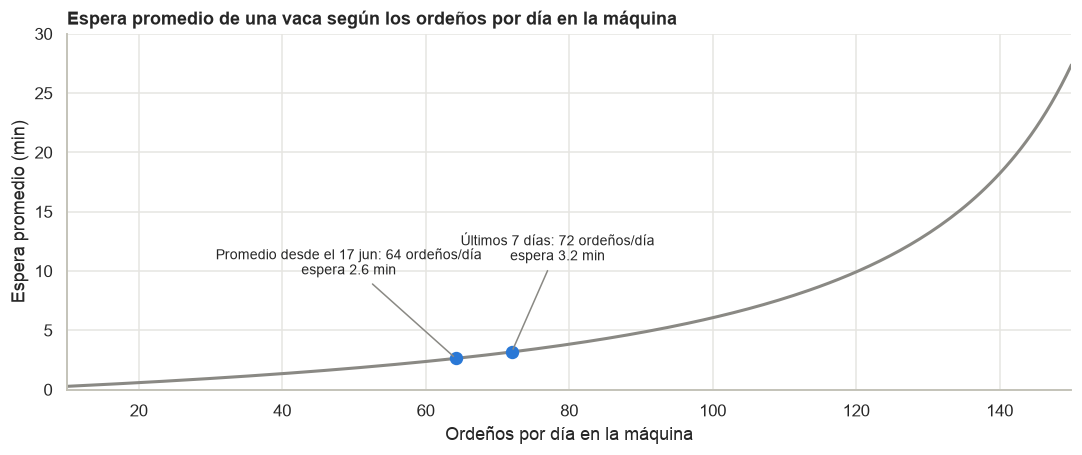

 ordeños_por_día  ocupación_pct  espera_promedio_min
              40           22.9                  1.3
              65           37.2                  2.7
              80           45.8                  3.8
             100           57.2                  6.1
             120           68.6                  9.9
             140           80.1                 18.2


In [34]:
media_servicio = cola["duracion_min"].mean()
variacion = cola["duracion_min"].std() / media_servicio   # coeficiente de variacion de la duracion


def espera_promedio(ordenos_por_dia):
    """Espera promedio en minutos de una vaca (formula de Pollaczek-Khinchine)."""
    ocupacion = ordenos_por_dia * media_servicio / 1440
    return ocupacion * media_servicio * (1 + variacion ** 2) / (2 * (1 - ocupacion))


# Carga de todo el periodo y de los ultimos 7 dias completos (el ultimo dia esta incompleto)
ultimo_dia = cola["fecha"].max()
ultima_semana = cola[(cola["fecha"] >= ultimo_dia - pd.Timedelta(days=7)) & (cola["fecha"] < ultimo_dia)]
puntos = {"Promedio desde el 17 jun": len(cola) / dias_despues, "Últimos 7 días": len(ultima_semana) / 7}

carga = np.linspace(10, 150, 200)
fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(carga, espera_promedio(carga), color=GRIS, linewidth=2)
desplazamientos = [(-70, 55), (30, 60)]   # una anotacion a la izquierda y otra a la derecha para que no se encimen
for (nombre, valor), desplazamiento in zip(puntos.items(), desplazamientos):
    ax.scatter(valor, espera_promedio(valor), color=color_maquina[principal], s=60, zorder=3)
    ax.annotate(f"{nombre}: {valor:.0f} ordeños/día\nespera {espera_promedio(valor):.1f} min",
                (valor, espera_promedio(valor)), textcoords="offset points", xytext=desplazamiento, ha="center", fontsize=9,
                arrowprops=dict(arrowstyle="-", color=GRIS))
ax.set_title("Espera promedio de una vaca según los ordeños por día en la máquina")
ax.set_xlabel("Ordeños por día en la máquina")
ax.set_ylabel("Espera promedio (min)")
ax.set_ylim(0, 30)
ax.set_xlim(10, 150)
plt.tight_layout()
plt.show()

print(pd.DataFrame({"ordeños_por_día": [40, 65, 80, 100, 120, 140]})
      .assign(ocupación_pct=lambda t: t["ordeños_por_día"] * media_servicio / 1440 * 100,
              espera_promedio_min=lambda t: espera_promedio(t["ordeños_por_día"])).round(1).to_string(index=False))

**Observaciones:**
- **La máquina tiene margen, pero la espera crece rápido.** Espera promedio estimada: 1.3 min con 40 ordeños por día, 2.7 con 65, 6.1 con 100, 9.9 con 120 y 18.2 con 140. La carga actual es de 64 ordeños por día en promedio desde el 17 de junio y 72 en los últimos 7 días (espera estimada de 3.2 min). La espera superaría los 10 minutos con unos 120 ordeños por día, cerca de 1.7 veces la carga de la última semana.
- La fórmula supone llegadas al azar. Si las vacas llegan agrupadas, como sugiere la sección 7.1, la espera real sería mayor. El promedio de la fórmula con la carga promedio (2.6 min) coincide con el de la simulación (2.8 min).

**Conclusión:**
- Con estos datos no se ve un problema de cola grave en la máquina única. Lo observado equivale a lo que darían llegadas al azar con esa carga: espera estimada de unos 3 min en promedio, y alrededor de 1 de cada 10 vacas esperaría más de 10 min. Es una estimación, no una medición.
- Hay congestión moderada y creciente. Hay horas con más relevos pegados de lo esperado (sobre todo a las 20:00) y la espera subiría con rapidez si el hato crece o la carga pasa de unos 100 ordeños por día.
- Para confirmar el diagnóstico falta la hora de llegada de cada vaca (por ejemplo, un sensor en la entrada) y que el CAETEC indique cuántos minutos de espera consideran un problema.

## 8. Resumen de hallazgos y pendientes

**El dataset**

- 7,249 visitas de 34 vacas a 3 robots, del 1 de marzo al 18 de julio de 2025. 7,016 son ordeños.
- Desde el 17 de junio casi todos los ordeños ocurren en una sola máquina (`7063e4b1`); antes se repartían entre las tres.
- 36 columnas: 3 no aportan nada (`estado_rcs_1000_celulas_ml`, `misc_usuario`, `misc_razon_de_la_desviacion`).

**Calidad**

- Nulos: casi todos son estructurales (visita sin ordeño) o significan "no ocurrió". Los problemas reales son los ceros de conductividad y dos vacas con un cuarto sin medición.
- Duplicados: 2 exactos. Los pares `Ordeño` + `Echada sin ordeñar` del 16/03 y 27/06 necesitan explicación antes de decidir qué hacer.
- Tipos: fecha, duración y eventos requieren transformación antes de usarse.

**Preguntas para el socio formador**

- ¿Qué pasó el 16/03/2025 y el 27/06/2025 (registros `Echada sin ordeñar` pareados con un ordeño)?
- ¿Las vacas `7648b6a6` y `505279da` tienen un cuarto que no se ordeña?
- ¿El sensor de conductividad del cuarto TD de la máquina `b96e85be` está fallando? Registra 0 en 96 % de sus ordeños.
- ¿Por qué el hato pasó a una sola máquina a mediados de junio (falla, mantenimiento o decisión de manejo)?
- ¿Qué significan exactamente `AMD ubre` y `AMD pezón`, y `Divert 3` como destino de la leche?